# D60 RAG Serving Opt Code

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11

## RAG 서빙 최적화 구현 실습

## 오늘 확인할 문제

**모델의 생성 속도를 높였는데도 RAG 답변이 늦다면 어느 단계부터 확인해야 합니까?**

교육장 안내 챗봇이 문서를 검색해 답하려면 생성 전에 질문 임베딩, 문서 검색, 검색 결과 재정렬을 수행합니다. 오늘은 각 단계에 걸린 시간을 따로 측정해 가장 오래 걸리는 부분을 찾습니다. 설정을 하나씩 바꾸면서 필요한 문서를 찾는지, 답이 맞는지, 권한이 없는 문서가 섞이지 않는지도 확인합니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 작은 생성 모델과 검색 구성 요소를 연결해 RAG 요청의 구간별 시간을 측정할 수 있다.
- [목표 2] 청크·캐시·프롬프트 순서를 하나씩 바꾸며 정답·근거·권한 문제를 비교할 수 있다.
- [목표 3] 실패와 잃은 정답을 확인해 최적화할 설정을 선택하고 결과를 보관할 수 있다.

오늘은 지금까지 만든 RAG 스택을 그대로 구성하고 질문 하나가 답이 되기까지의 시간을 구간별로 측정합니다.

그다음 설정을 **한 번에 하나씩** 바꿉니다. 설정 하나를 바꿀 때마다 같은 질문 세트로 품질이 그대로인지 확인하고 flip을 셉니다.

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 검색 구성과 단계별 시간 측정 | 100분 | 이론 1장, Step 0\~3 |
| 청크·캐시 설정별 답변 비교 | 105분 | 이론 2·4장, Step 4\~5 |
| 문서 배치와 답변 모델 선택 | 85분 | 이론 3·5장, Step 6\~7 |
| 설정 선택과 모듈 결과 정리 | 70분 | 이론 6장, Step 9 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

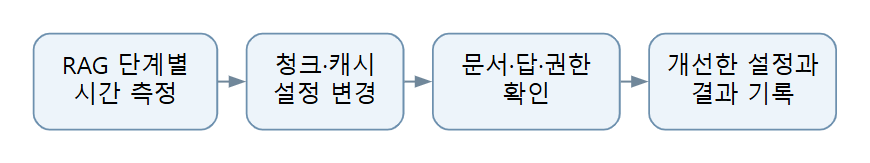

**실습 순서.** RAG 단계별 시간 측정 → 청크·캐시 설정 변경 → 문서·답·권한 확인 → 개선한 설정과 결과 기록 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| RAG |  질문과 관련된 문서를 검색해 모델의 입력에 붙여 답하는 구성 |
| 청크 |  검색하고 입력에 넣기 위해 문서를 나눈 조각 |
| 재정렬 |  검색한 후보 문서에 다시 점수를 매겨 순서를 바꾸는 처리 |
| 폴백 |  첫 처리 경로가 실패하거나 기준을 못 맞췄을 때 다른 경로로 처리하는 동작 |

## 실행 환경

| 항목 | 내용 |
|---|---|
| 기준 환경 | 코랩 Pro+ T4 (16GB). GPU가 없거나 vLLM 서버가 기동되지 않으면 부록 실습 A의 mock 서버나 transformers 모드로 바꿔 끝까지 실행됩니다. 허브에 연결되지 못할 때의 mock 검색 모델도 부록 실습 A에 있습니다 |
| 로드하는 모델 | 4개. 임베딩 `intfloat/multilingual-e5-small`, 재정렬 `BAAI/bge-reranker-v2-m3`, 생성 큰 모델 `Qwen/Qwen2.5-1.5B-Instruct`, 작은 모델 `Qwen/Qwen2.5-0.5B-Instruct` |
| 기동하는 서버 | Qdrant 1.19.1(8600), 큰 모델 vLLM 서버(8602), 작은 모델 vLLM 서버(8603). 포트가 사용 중이면 `D60_PORT`로 시작 번호를 바꿉니다 |
| 생성 서버 | vLLM 기초 노트와 같은 방식입니다. `vllm serve`를 별도 프로세스로 기동하고 OpenAI 호환 주소를 호출합니다 |
| 오래 걸리는 셀 | Step 0 vLLM 설치 3\~6분, Step 2 vLLM 서버 두 대 기동 각 3\~8분(처음 받는 모델 포함), Step 3\~7 측정 셀 각 1\~3분 |
| 외부 통신 | 모델과 Qdrant 실행 파일 다운로드뿐입니다. 질문과 문서는 런타임 밖으로 나가지 않습니다 |
| 결과 파일 | `/content/d60/d60_results.json` (Step 9). MLOps 소개 노트가 `meta`와 `runs`의 `기준선`, `고른 설정`을 읽으므로 이름과 키를 바꾸지 않습니다 |
| 전체 소요 | 이론·필수 실습 360분, 휴식·점심·오류 대응 여유 포함 480분 계획. 선택 트랙은 별도 |

생성 모드는 `D60_GEN` 환경 변수로 고릅니다. 아무것도 정하지 않으면 GPU가 있을 때 `vllm`, 없을 때 `fake`(mock 서버)가 됩니다. `fake`와 `local`(vLLM 없이 transformers로 생성) 모드에서는 Step 1의 요청 목록(`TRAFFIC`) 셀 다음에 노트 끝의 부록 실습 A를 먼저 실행합니다.

**로컬 작업**
사내 서버에서는 임베딩, 재정렬, 생성이 대개 서로 다른 GPU나 서버에 있습니다. 오늘은 임베딩·재정렬은 CPU에서 실행하고 생성 모델 두 개만 GPU를 나눠 씁니다. 사내에서 같은 측정을 하면 구간별 측정값이 달라지고 특히 네트워크 왕복이 한 구간으로 더해집니다.

## Step 0. 환경 준비

버전은 앞 노트들과 같은 지정을 씁니다.

In [1]:
# 버전에 상한을 둡니다
!pip install -q "qdrant-client>=1.19,<2" "sentence-transformers>=6,<7" "openai>=3.16,<4" \
                "transformers>=5.17,<6" "accelerate>=1.15,<2" "httpx>=0.28,<1" \
                "fastapi>=0.141,<0.142" "uvicorn[standard]>=0.53,<0.54" "rank_bm25==0.2.2"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vllm 0.30.0 requires fastapi[standard]<0.137.0,>=0.133.0, but you have fastapi 0.141.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
# 이 셀은 torch를 불러오기 전에 실행합니다.
import os, shutil, subprocess
has_driver=bool(shutil.which("nvidia-smi"))
requested=os.environ.get("D60_GEN","vllm" if has_driver else "fake")
if requested=="vllm":
    !pip install -q "vllm>=0.30,<0.31"
    print("설치 뒤 Colab의 [런타임] > [세션 다시 시작]을 실행하고 다음 셀부터 이어갑니다.")
else:
    print("모의·local 경로는 vLLM 설치를 건너뜁니다. 다음 셀에서 생성 모드를 확인합니다.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
설치 뒤 Colab의 [런타임] > [세션 다시 시작]을 실행하고 다음 셀부터 이어갑니다.


In [3]:
import os, torch
HAS_GPU=torch.cuda.is_available()
GEN=os.environ.get("D60_GEN", "vllm" if HAS_GPU else "fake")
print("생성 모드:",GEN,"GPU:",torch.cuda.get_device_name(0) if HAS_GPU else "없음")

생성 모드: vllm GPU: Tesla T4


In [4]:
import hashlib, json, re, subprocess, sys, time
from pathlib import Path

import numpy as np
import requests


# 포트 4개. 사용 중이면 D60_PORT 를 바꿉니다
BASE_PORT = int(os.environ.get("D60_PORT", "8600"))
QDRANT_PORT, QDRANT_GRPC, BIG_PORT, SMALL_PORT = range(BASE_PORT, BASE_PORT + 4)

WORK = Path(os.environ.get("D60_WORK", "/content/d60"))
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)                      # %%writefile 파일이 여기 생기고 import 됩니다
sys.path.insert(0, str(WORK))
DEVICE = "cuda" if HAS_GPU else "cpu"
print("작업 폴더", WORK, "/ 포트", BASE_PORT, "부터 4개")

작업 폴더 /content/d60 / 포트 8600 부터 4개


## Step 1. 사내 문서와 검색 단계

교재 : 4.5.1 벡터 데이터베이스, 6.8 검색 재정렬기 파이프라인을 활용한 RAG 자동화

문서는 양자화 노트 코드의 한결물산 근무 규정(실습용으로 지어낸 문서)을 늘려 만듭니다. 문서마다 **부서** 필드를 붙여 인사, 재무, 영업, 보안 문서는 그 부서 사람만 보게 합니다.

In [5]:
DOCS = [dict(id=i, 부서=p, 제목=t, 본문=b, 버전=1) for i, p, t, b in [
    ("공개-01", "공개", "근무 시간", "기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다."),
    ("공개-02", "공개", "재택근무", "재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다. 재택근무 중에도 오전 10시부터 오후 4시까지는 메신저에 접속해 있어야 한다."),
    ("공개-03", "공개", "연차 휴가", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다. 쓰지 못한 연차는 다음 해로 넘기지 않는다."),
    ("공개-04", "공개", "반차", "반차는 하루 근무 시간의 절반인 4시간으로 계산하며 연차 0.5일을 쓴 것으로 본다. 오전 반차는 오후 2시에 출근하고 오후 반차는 오후 1시에 퇴근한다. 반차는 한 달에 4번까지 쓸 수 있다."),
    ("공개-05", "공개", "국내 출장비", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다."),
    ("공개-06", "공개", "해외 출장비", "해외 출장의 숙박비는 1박에 20만 원까지 실비로 지급한다. 일비는 하루 5만 원을 정액으로 지급한다. 귀국한 뒤 10일 안에 정산을 신청한다."),
    ("공개-07", "공개", "정보 보안", "회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다."),
    ("공개-08", "공개", "경조 휴가", "본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다. 경조 휴가는 사유가 생긴 날부터 30일 안에 쓴다."),
    ("공개-09", "공개", "교육 지원", "직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다. 같은 교육을 두 번 지원받을 수는 없다."),
    ("공개-10", "공개", "장비 대여", "업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 업무용 노트북은 4년마다 바꿔 준다."),
    ("공개-11", "공개", "법인카드 사용", "법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다. 영수증은 결제한 달 안에 시스템에 올린다."),
    ("공개-12", "공개", "회의", "정기 회의는 매주 월요일 오전 10시에 연다."),
    ("공개-13", "공개", "야근 식대", "오후 8시 이후까지 일한 직원에게는 식대 1만 원을 지급한다."),
    ("공개-14", "공개", "건강검진", "건강검진은 2년에 1번 받는다. 만 40세 이상 직원은 해마다 받는다. 검진일은 유급 휴가로 처리한다."),
    ("공개-15", "공개", "육아휴직", "육아휴직은 자녀 한 명당 최대 1년까지 쓸 수 있다. 휴직을 시작하기 30일 전까지 인사팀에 신청한다. 휴직 기간도 근속 기간에 넣는다."),
    ("공개-16", "공개", "주차 지원", "회사 건물 주차장은 임원과 장애인 직원에게 먼저 배정한다. 나머지 직원에게는 월 주차비를 7만 원까지 지원한다."),
    ("공개-17", "공개", "동호회 지원", "회원이 5명 이상인 사내 동호회에는 회원 1명당 한 달에 2만 원을 지원한다. 지원금은 분기마다 정산한다."),
    ("공개-18", "공개", "규정 개정", "이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."),
    ("인사-01", "인사", "평가 등급", "평가 등급은 S, A, B, C 네 단계이다. S 등급은 팀별 상위 10퍼센트로 제한한다. 등급은 12월 둘째 주에 확정한다."),
    ("인사-02", "인사", "성과급", "S 등급의 성과급은 기본급의 200퍼센트이고 A 등급은 150퍼센트이다."),
    ("인사-03", "인사", "승진 심사", "승진 심사를 받으려면 현재 직급에서 3년 이상 근무해야 한다."),
    ("재무-01", "재무", "법인카드 한도", "법인카드의 월 한도는 300만 원이다. 한도를 올리려면 재무팀장의 승인을 받는다. 한도 상향은 최대 3개월 동안 유지된다."),
    ("재무-02", "재무", "예산 전용", "분기 예산의 10퍼센트 안에서는 팀장 승인으로 다른 항목에 옮겨 쓸 수 있다."),
    ("영업-01", "영업", "4분기 영업 목표", "4분기 목표는 3분기 실적의 120퍼센트이다. 신규 계약 비중은 절반 이상으로 한다. 주간 실적은 매주 월요일에 집계한다."),
    ("영업-02", "영업", "할인 승인", "정가에서 15퍼센트를 넘게 할인하려면 영업본부장의 승인을 받는다."),
    ("보안-01", "보안", "보안 사고 등급", "1등급 보안 사고는 30분 안에 정보보호팀장에게 보고한다. 2등급 사고는 4시간 안에 보고한다."),
]]

USERS = {"김공개": ["공개"], "정공개": ["공개"], "박인사": ["공개", "인사"],
         "이영업": ["공개", "영업"], "최재무": ["공개", "재무"]}

from collections import Counter
print(f"문서 {len(DOCS)}건 :", dict(Counter(d["부서"] for d in DOCS)))

문서 26건 : {'공개': 18, '인사': 3, '재무': 2, '영업': 2, '보안': 1}


질문 세트는 **숫자로 답이 정해지는 질문**만 고릅니다. 볼 수 없는 사람에게는 정답이 `None`, 곧 "근거를 찾지 못했습니다"입니다.

In [6]:
QUESTIONS = [dict(id=f"Q{i:02d}", user=u, q=t, answer=a, 근거=b, kind=k) for i, (u, t, a, b, k) in enumerate([
    ("김공개", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2, ["공개-02"], "조회"),
    ("김공개", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3, ["공개-02"], "조회"),
    ("김공개", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15, ["공개-03"], "조회"),
    ("김공개", "반차는 몇 시간으로 계산합니까?", 4, ["공개-04"], "조회"),
    ("김공개", "국내 출장의 1박 숙박비는 최대 몇 만 원입니까?", 10, ["공개-05"], "조회"),
    ("김공개", "해외 출장의 1박 숙박비는 최대 몇 만 원입니까?", 20, ["공개-06"], "조회"),
    ("김공개", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1, ["공개-07"], "조회"),
    ("김공개", "본인 결혼 때 경조 휴가는 며칠입니까?", 5, ["공개-08"], "조회"),
    ("김공개", "자녀 결혼 때 경조 휴가는 며칠입니까?", 1, ["공개-08"], "조회"),
    ("김공개", "외부 교육비는 1년에 최대 몇 만 원까지 지원됩니까?", 100, ["공개-09"], "조회"),
    ("김공개", "법인카드로 한 번에 몇 만 원을 넘게 결제하면 사전 승인이 필요합니까?", 50, ["공개-11"], "조회"),
    ("김공개", "육아휴직은 시작하기 며칠 전까지 신청해야 합니까?", 30, ["공개-15"], "조회"),
    ("김공개", "건강검진은 몇 년에 한 번 받습니까?", 2, ["공개-14"], "조회"),
    ("김공개", "국내 출장을 3박 4일로 다녀오면 숙박비 상한과 식비를 합해 최대 몇 만 원을 받습니까?", 42, ["공개-05"], "계산"),
    ("김공개", "연차 15일 가운데 반차를 3번 썼다면 남은 연차는 며칠입니까?", 13.5, ["공개-03", "공개-04"], "계산"),
    ("김공개", "해외 출장 2박 3일의 숙박비 상한과 일비를 합하면 최대 몇 만 원입니까?", 55, ["공개-06"], "계산"),
    ("김공개", "회원이 6명인 동호회는 한 달에 모두 몇 만 원을 지원받습니까?", 12, ["공개-17"], "계산"),
    ("박인사", "S 등급은 팀별 상위 몇 퍼센트입니까?", 10, ["인사-01"], "권한"),
    ("이영업", "S 등급은 팀별 상위 몇 퍼센트입니까?", None, [], "권한"),
    ("최재무", "법인카드의 월 한도는 몇 만 원입니까?", 300, ["재무-01"], "권한"),
    ("김공개", "법인카드의 월 한도는 몇 만 원입니까?", None, [], "권한"),
    ("이영업", "4분기 영업 목표는 3분기 실적의 몇 퍼센트입니까?", 120, ["영업-01"], "권한"),
    ("김공개", "4분기 영업 목표는 3분기 실적의 몇 퍼센트입니까?", None, [], "권한"),
    ("김공개", "주차비는 한 달에 몇 만 원까지 지원됩니까?", 7, ["공개-16"], "조회"),
    ("김공개", "국내 출장 4일 동안 받는 식비는 몇 만 원입니까?", 12, ["공개-05"], "계산"),
], start=1)]
print(f"질문 {len(QUESTIONS)}개 :", dict(Counter(x["kind"] for x in QUESTIONS)), f"/ 한 문항 {1 / len(QUESTIONS):.0%}")

질문 25개 : {'조회': 14, '계산': 5, '권한': 6} / 한 문항 4%


캐시를 테스트할 때는 질문 세트를 **들어오는 순서가 있는 요청 목록**으로 바꿔 씁니다.

In [7]:
QMAP = {x["id"]: x for x in QUESTIONS}


def ask(qid, user=None, text=None):
    """(사람, 질문, 기본 질문 id). 순서가 들어오는 순서"""
    return (user or QMAP[qid]["user"], text or QMAP[qid]["q"], qid)


TRAFFIC = [ask("Q01"), ask("Q01", text="재택근무 일주일에 며칠까지 돼요?"),    # 같은 뜻, 다른 말
           ask("Q01", "정공개", "재택근무는 주 며칠까지 가능합니까?"),        # 같은 범위의 다른 사람
           ask("Q02"),                                                        # 글자가 비슷, 답이 다름
           ask("Q03"), ask("Q03", "정공개", "연차는 1년에 며칠 나옵니까?"), ask("Q04"), ask("Q05"), ask("Q06"),
           ask("Q08"), ask("Q09", "정공개"), ask("Q18"), ask("Q19"),          # Q18·Q19 : 같은 글자, 다른 권한
           ask("Q20"), ask("Q21"), ask("Q22"), ask("Q23"), ask("Q01")]       # 마지막은 똑같은 질문

#### 검색 단계

벡터DB 노트와 에어갭 RAG 노트처럼 Qdrant를 **별도 서버 프로세스**로 기동합니다.

In [8]:
QDRANT_VER = os.environ.get("D60_QDRANT_VER", "v1.19.1")
QBIN = WORK / "qdrant"
if not QBIN.exists():
    url = f"https://github.com/qdrant/qdrant/releases/download/{QDRANT_VER}/qdrant-x86_64-unknown-linux-gnu.tar.gz"
    subprocess.run(f"wget -q {url} -O qdrant.tar.gz && tar -xzf qdrant.tar.gz", shell=True, check=True)
    QBIN.chmod(0o755)
(WORK / "qdrant_config.yaml").write_text(
    f"storage:\n  storage_path: {WORK / 'qdrant_storage'}\nservice:\n  host: 127.0.0.1\n"
    f"  http_port: {QDRANT_PORT}\n  grpc_port: {QDRANT_GRPC}\nlog_level: WARN\ntelemetry_disabled: true\n")
QDRANT_URL = f"http://127.0.0.1:{QDRANT_PORT}"


def wait_health(url, proc, name, wait):
    """서버가 답할 때까지 기다립니다. 실패하면 로그 파일을 안내합니다"""
    for i in range(wait):
        if proc.poll() is not None:
            break
        try:
            if requests.get(url, timeout=1).status_code == 200:
                return print(f"[{name}] 기동 완료 ({i + 1}초)") or proc
        except requests.exceptions.RequestException:
            pass
        time.sleep(1)
    print(f"[{name}] 기동되지 않았습니다. {WORK / name}.log 를 보세요")
    return proc


def start_qdrant():
    global qdrant_proc
    qdrant_proc = subprocess.Popen([str(QBIN), "--config-path", str(WORK / "qdrant_config.yaml")],
                                   stdout=open(WORK / "qdrant.log", "w"), stderr=subprocess.STDOUT)
    wait_health(f"{QDRANT_URL}/healthz", qdrant_proc, "qdrant", 40)


start_qdrant()

[qdrant] 기동 완료 (2초)


In [9]:
%%writefile d60_standin.py
"""허브에 연결되지 못할 때 쓰는 mock 두 개. 진짜 모델과 호출하는 형식만 같습니다.

mock 임베딩 : 글자 두세 개 단위(n-gram)를 해시해 384차원에 더한 벡터입니다. 뜻이 아니라 글자가 겹치는 정도를 봅니다
mock 재정렬 : 질문과 문서가 함께 가진 두 글자 단위의 비율입니다
"""
import hashlib

import numpy as np


def _grams(text, ns=(2, 3)):
    t = "".join(text.split())
    return [t[i:i + n] for n in ns for i in range(len(t) - n + 1)]


class StandInEmbedder:
    dim = 384

    def get_embedding_dimension(self):
        return self.dim

    def encode(self, texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False):
        out = np.zeros((len(texts), self.dim), dtype=np.float32)
        for row, text in enumerate(texts):
            for g in _grams(text.replace("query: ", "").replace("passage: ", "")):
                h = int.from_bytes(hashlib.md5(g.encode()).digest()[:4], "little")
                out[row, h % self.dim] += 1.0 if (h >> 31) & 1 else -1.0
        if normalize_embeddings:
            out /= np.linalg.norm(out, axis=1, keepdims=True) + 1e-9
        return out


class StandInReranker:
    def predict(self, pairs, batch_size=32, show_progress_bar=False):
        scores = []
        for query, passage in pairs:
            a, b = set(_grams(query, (2,))), set(_grams(passage, (2,)))
            scores.append(len(a & b) / (len(a) + 1e-9))
        return np.array(scores, dtype=np.float32)

Overwriting d60_standin.py


In [10]:
from sentence_transformers import SentenceTransformer, CrossEncoder

# 모델 이름과 버전은 환경 변수에서 읽습니다(사내에서는 커밋 해시)
EMB_ID = os.environ.get("D60_EMB_ID", "intfloat/multilingual-e5-small")
EMB_REV = os.environ.get("D60_EMB_REV", "main")
RERANK_ID = os.environ.get("D60_RERANK_ID", "BAAI/bge-reranker-v2-m3")
try:
    emb_model, EMB_NAME = SentenceTransformer(EMB_ID, revision=EMB_REV, device="cpu"), f"{EMB_ID}@{EMB_REV}"
    reranker = CrossEncoder(RERANK_ID, max_length=512, device="cpu", model_kwargs={"dtype": torch.float32})
    RERANK_NAME = RERANK_ID
except Exception as e:      # 허브에 연결되지 못하면 mock (파일은 부록 실습 A가 만듭니다)
    print(f"[mock] {type(e).__name__} : mock 임베딩과 재정렬을 씁니다")
    from d60_standin import StandInEmbedder, StandInReranker
    emb_model, EMB_NAME, reranker, RERANK_NAME = StandInEmbedder(), "mock-해시-384", StandInReranker(), "mock-겹침"
DIM, STANDIN = emb_model.get_embedding_dimension(), EMB_NAME.startswith("mock")   # 차원은 모델에 묻습니다
print(f"임베딩 {EMB_NAME} ({DIM}차원) / 재정렬 {RERANK_NAME}")


def embed(texts, kind):
    """e5 계열은 질문과 문서에 접두어를 붙입니다"""
    return emb_model.encode([("query: " if kind == "query" else "passage: ") + t for t in texts],
                            normalize_embeddings=True)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

임베딩 intfloat/multilingual-e5-small@main (384차원) / 재정렬 BAAI/bge-reranker-v2-m3


In [11]:
from qdrant_client import QdrantClient
from qdrant_client.models import (Distance, FieldCondition, Filter, MatchAny, PointStruct,
                                  SearchParams, VectorParams, PayloadSchemaType)

qc = QdrantClient(url=QDRANT_URL)
COLL = "d60_docs"


def index_docs(docs):
    """문서를 통째로 다시 인덱싱합니다"""
    if qc.collection_exists(COLL):
        qc.delete_collection(COLL)
    qc.create_collection(COLL, vectors_config=VectorParams(size=DIM, distance=Distance.COSINE))
    qc.create_payload_index(COLL, field_name="부서", field_schema=PayloadSchemaType.KEYWORD)
    vecs = embed([f"{d['제목']}\n{d['본문']}" for d in docs], "passage")
    qc.upsert(COLL, points=[PointStruct(id=i, vector=v.tolist(), payload=d) for i, (v, d) in enumerate(zip(vecs, docs))])
    return qc.get_collection(COLL).points_count


print(f"인덱싱 완료 : {index_docs(DOCS)}건")

인덱싱 완료 : 26건


In [12]:
def search(qvec, depts, limit=20, ef=128):
    """부서 필터를 검색 안에 넣습니다(나중에 거르지 않습니다)"""
    flt = Filter(must=[FieldCondition(key="부서", match=MatchAny(any=list(depts)))])
    hits = qc.query_points(COLL, query=qvec.tolist(), query_filter=flt, limit=limit,
                           search_params=SearchParams(hnsw_ef=ef)).points
    return [{**h.payload, "score": float(h.score)} for h in hits]


def rerank(question, cands):
    scores = reranker.predict([(question, f"{c['제목']}\n{c['본문']}") for c in cands]) if cands else []
    for c, s in zip(cands, scores):
        c["rerank"] = float(s)
    return sorted(cands, key=lambda c: -c["rerank"])

## Step 2. 생성 서버 기동

교재 : 6.11 다중모델 오케스트레이션

생성 서버는 vLLM 기초 노트처럼 `vllm serve`를 별도 프로세스로 기동하고 OpenAI 호환 주소로 호출합니다. 서빙 프로젝트 노트 2절의 서버(`POST /chat`)에 붙일 때도 `model_service.generate_reply` 안에서 이 주소를 호출하면 됩니다.

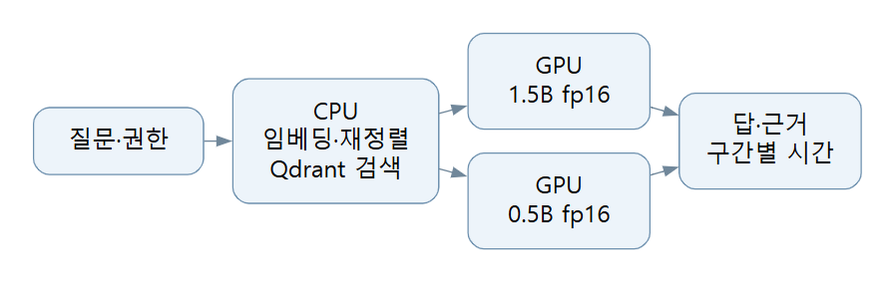

**그림.** 기본 vLLM 경로의 구성 개념도입니다. 임베딩·재정렬·검색은 CPU에서, 1.5B·0.5B 생성은 GPU에서 실행합니다. 모의 경로의 수치와 실제 GPU 측정값은 따로 기록합니다.

큰 모델과 작은 모델을 서버 두 대로 기동합니다.

**서버를 기동할 때 켜는 설정**

- `--enable-prompt-tokens-details` : 응답의 `usage`에 캐시에 적중한 입력 토큰 수(`cached_tokens`)를 싣습니다. Step 6에서 씁니다  
- `--enable-per-request-metrics` : 서버가 측정한 첫 토큰 시간, 대기 시간, 생성 시간을 응답에 싣습니다. 클라이언트에서 측정한 시간과 비교합니다  
- 환경 변수 `VLLM_SERVER_DEV_MODE=1` : 프리픽스 캐시를 비우는 `/reset_prefix_cache` 주소를 엽니다. **실습에서만 켭니다.** 개발용 주소가 함께 열리므로 사내 서버에서는 끕니다

**메모리 계획:** 기본 경로는 1.5B·0.5B fp16 생성 서버와 CPU 임베딩·재정렬입니다. 생성 서버는 eager 실행으로 컴파일 메모리를 줄입니다. 이 조건은 D57의 32B 서빙 성능과 직접 비교하지 않습니다. 두 서버의 동시 기동은 실제 Colab GPU에서 사전 확인이 필요하며, 실패하면 로그를 확인하고 명시적으로 모의 경로를 선택합니다.

In [13]:
BIG_ID = os.environ.get("D60_BIG_ID", "Qwen/Qwen2.5-1.5B-Instruct")
SMALL_ID = os.environ.get("D60_SMALL_ID", "Qwen/Qwen2.5-0.5B-Instruct")
MEM = {"big": os.environ.get("D60_BIG_MEM", "0.45"), "small": os.environ.get("D60_SMALL_MEM", "0.20")}
MAX_LEN = os.environ.get("D60_MAX_LEN", "4096")


def start_llm(role, model_id, port):
    """생성 서버 하나를 기동하고 /health 가 답할 때까지 기다립니다"""
    if GEN == "vllm":
        cmd = ["vllm", "serve", model_id, "--host", "127.0.0.1", "--port", str(port), "--dtype", "half",
               "--max-model-len", MAX_LEN, "--gpu-memory-utilization", MEM[role],
               "--enable-prompt-tokens-details", "--enable-per-request-metrics", "--enforce-eager"]
        env, wait = {**os.environ, "VLLM_SERVER_DEV_MODE": "1"}, 900
    else:                    # mock 서버 파일은 부록 실습 A가 만듭니다
        cmd = [sys.executable, "-m", "uvicorn", "fake_llm_server:app", "--host", "127.0.0.1",
               "--port", str(port), "--log-level", "warning"]
        env, wait = {**os.environ, "D60_FAKE_ROLE": role, "D60_FAKE_MODEL": model_id,
                     "D60_FAKE_KEY": str(WORK / "fake_key.json")}, 60
    log = open(WORK / f"llm_{role}.log", "w")
    return wait_health(f"http://127.0.0.1:{port}/health", subprocess.Popen(cmd, stdout=log, stderr=log, env=env), f"llm_{role}", wait)


LLM_PROCS = {}
if GEN in ("vllm", "fake"):              # local 모드는 부록 실습 A
    LLM_PROCS = {"big": start_llm("big", BIG_ID, BIG_PORT), "small": start_llm("small", SMALL_ID, SMALL_PORT)}

[llm_big] 기동 완료 (48초)
[llm_small] 기동 완료 (47초)


클라이언트 코드는 모드와 상관없이 함수 하나로 씁니다. **첫 토큰이 온 순간**과 **마지막 토큰이 온 순간**을 따로 적고 실패는 예외로 던지지 않고 `error` 필드에 적어 반환합니다. 서버가 응답하는지는 Step 3의 첫 측정에서 `error` 열로 확인합니다.

In [14]:
import httpx
from openai import OpenAI

ROUTES = {"big": (BIG_PORT, BIG_ID), "small": (SMALL_PORT, SMALL_ID)}
CLIENTS = {r: OpenAI(base_url=f"http://127.0.0.1:{p}/v1", api_key="local", max_retries=0) for r, (p, _) in ROUTES.items()}


def chat_stream(route, messages, max_tokens, chunk_timeout=None, salt=None):
    """생성 한 번. 실패는 예외 대신 error 에 적습니다"""
    out = dict(route=route, text="", ttft_ms=None, rest_ms=None, total_ms=None,
               prompt_tokens=None, cached_tokens=None, server=None, error=None)
    t0 = time.perf_counter()
    try:
        client = CLIENTS[route].with_options(timeout=httpx.Timeout(chunk_timeout or 120.0, connect=3.0))
        stream = client.chat.completions.create(
            model=ROUTES[route][1], messages=messages, max_tokens=max_tokens, temperature=0, stream=True,
            stream_options={"include_usage": True}, extra_body={"cache_salt": salt} if salt else None)
        for chunk in stream:
            if chunk.choices and chunk.choices[0].delta.content:  # 첫 텍스트 청크
                out["ttft_ms"] = out["ttft_ms"] or (time.perf_counter() - t0) * 1000
                out["text"] += chunk.choices[0].delta.content
            if chunk.usage:
                out["prompt_tokens"] = chunk.usage.prompt_tokens
                out["cached_tokens"] = getattr(chunk.usage.prompt_tokens_details, "cached_tokens", None)
            out["server"] = (chunk.model_extra or {}).get("metrics") or out["server"]
    except Exception as e:                    # 시간 초과, 연결 거부, 서버 오류
        out["error"] = type(e).__name__
    out["total_ms"] = (time.perf_counter() - t0) * 1000
    if out["ttft_ms"]:
        out["rest_ms"] = out["total_ms"] - out["ttft_ms"]
    return out

HTTP 클라이언트의 시간 제한은 응답 청크가 오지 않는 대기 시간에 적용됩니다. 첫 토큰만의 절대 기한을 보장하는 설정은 아닙니다. `chunk_timeout`과 실측 첫 응답 시간을 구분하며, 실패한 요청도 `request_ms`에 실제 전체 대기 시간을 남깁니다.

## Step 3. RAG 단계별 시간 측정과 초기 결과

교재 : 7.2.1 실패 모드 조기 탐지, 3.4.3 애플리케이션에 가장 적합한 모델 선택하기

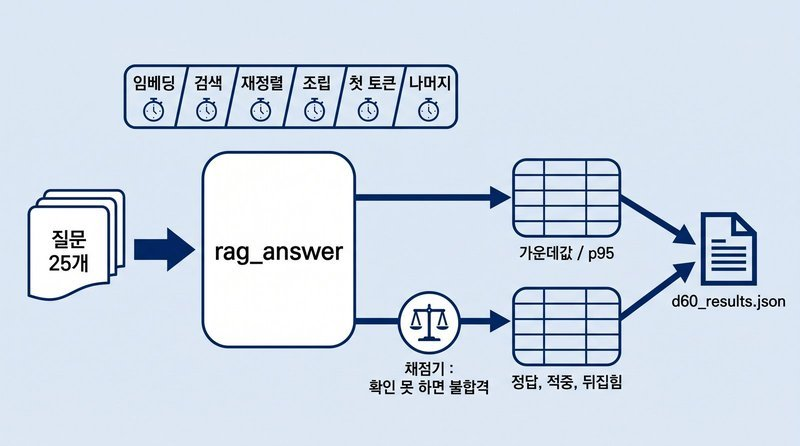

*설정을 바꿀 때마다 같은 질문으로 시간과 품질을 함께 측정해 한 행씩 남깁니다.*

오늘의 벤치마크 하네스는 요청 하나를 **임베딩, 캐시, 검색, 재정렬, 조립, 첫 토큰, 디코드** 구간으로 나눠 밀리초로 적습니다. 디코드 구간(decode, 첫 토큰 뒤 마지막 토큰까지)은 하네스의 구간 이름 `나머지`로 기록됩니다.

In [15]:
from contextlib import contextmanager


class Spans:
    """구간마다 걸린 밀리초를 모읍니다"""

    def __init__(self):
        self.ms = {}

    def add(self, name, ms):
        if ms is not None:
            self.ms[name] = self.ms.get(name, 0.0) + ms

    @contextmanager
    def span(self, name):
        t0 = time.perf_counter()
        try:
            yield
        finally:
            self.add(name, (time.perf_counter() - t0) * 1000)

시스템 메시지는 **모든 요청에서 글자 하나 다르지 않은** 규칙만 담습니다.

In [16]:
SYSTEM = """당신은 한결물산의 사내 규정 안내 담당자입니다. 답변은 반드시 한국어로만 작성하세요.
[답하는 규칙]
1. 사용자 메시지에 주어진 문서에 적힌 내용만 근거로 답합니다. 문서에 없는 내용은 지어내지 않습니다.
2. 첫 줄은 '답 : ' 뒤에 숫자 하나만 씁니다. 숫자 옆에 단위를 붙이지 않고 질문이 묻는 단위로 셈합니다.
3. 둘째 줄은 '근거 : ' 뒤에 쓴 문서의 번호를 씁니다. 예 : 공개-03
4. 셋째 줄은 '설명 : ' 뒤에 한 문장으로 씁니다.
5. 근거가 되는 문서가 없으면 첫 줄에 '답 : 근거를 찾지 못했습니다'라고 쓰고 숫자를 쓰지 않습니다.
6. 계산이 필요하면 문서의 숫자로 계산한 결과만 첫 줄에 씁니다.
7. 문서에 다른 부서의 규정이 섞여 있어도 질문에 맞는 문서만 씁니다."""


import uuid


def doc_block(d):
    return f"[문서 {d['id']} · 버전 {d['버전']}] {d['제목']}\n{d['본문']}"


def build_messages(question, user, ctx, layout="good-score"):
    """layout : bad / good-score(점수순) / good-id(문서 번호순)"""
    who = f"문의한 직원 : {user} ({', '.join(USERS[user])})"
    if layout == "good-id":
        ctx = sorted(ctx, key=lambda d: d["id"])
    docs = "\n\n".join(doc_block(d) for d in ctx)
    if layout == "bad":      # 시각과 request ID 를 맨 앞에 넣는 실수
        system = f"오늘 : {time.strftime('%Y-%m-%d %H:%M:%S')} / 요청 번호 : {uuid.uuid4().hex[:8]}\n{who}\n{SYSTEM}"
        user_msg = f"질문 : {question}\n\n{docs}"
    else:
        system, user_msg = SYSTEM, f"{docs}\n\n{who}\n오늘 : {time.strftime('%Y-%m-%d')}\n질문 : {question}"
    return [{"role": "system", "content": system}, {"role": "user", "content": user_msg}]


print(build_messages("반차는 몇 시간으로 계산합니까?", "김공개", DOCS[3:4])[1]["content"])

[문서 공개-04 · 버전 1] 반차
반차는 하루 근무 시간의 절반인 4시간으로 계산하며 연차 0.5일을 쓴 것으로 본다. 오전 반차는 오후 2시에 출근하고 오후 반차는 오후 1시에 퇴근한다. 반차는 한 달에 4번까지 쓸 수 있다.

문의한 직원 : 김공개 (공개)
오늘 : 2026-11-16
질문 : 반차는 몇 시간으로 계산합니까?


In [17]:
NUM = re.compile(r"-?\d+(?:\.\d+)?")


def grade(text, expect):
    """'답 :' 줄을 채점합니다. 확인하지 못하면 불합격"""
    line = next((l for l in (text or "").splitlines() if l.strip().startswith("답")), "")
    m = NUM.search(line.replace(",", ""))
    if expect is None:
        return m is None and "찾지 못" in line
    return m is not None and abs(float(m.group()) - float(expect)) < 1e-6


print(grade("답 : 2일\n근거 : 공개-02", 2), grade("근거 : 공개-02", 2), grade("답 : 근거를 찾지 못했습니다", None))   # True False True

True False True


In [18]:
# 후보 수, 넣는 청크 수, 답 길이 상한(Step 4) / 프롬프트 순서(Step 6) / 라우팅, 폴백, 응답 청크 대기 상한 초(Step 7) / 캐시, 솔트
BASE_CFG = dict(candidates=20, keep=5, max_tokens=300, layout="good-score", route="big", fallback=False,
                chunk_timeout=None, answer_cache=None, emb_cache=None, salt=None)


def rag_answer(question, user, cfg):
    request_started=time.perf_counter()
    rec, depts, ac = Spans(), USERS[user], cfg["answer_cache"]
    out = dict(spans=rec.ms, sources=[], cached_tokens=None, prompt_tokens=None, error=None, cache_from=None, server=None)
    with rec.span("임베딩"):
        qvec = cfg["emb_cache"].get(question) if cfg["emb_cache"] else embed([question], "query")[0]
    if ac:
        with rec.span("캐시"):
            hit = ac.lookup(question, qvec, depts)
        if hit:
            return {**out, "answer": hit["text"], "sources": hit["sources"], "route": f"캐시({hit['how']})", "cache_from": hit["from"], "request_ms": (time.perf_counter()-request_started)*1000}
    with rec.span("검색"):
        cands = search(qvec, depts, limit=cfg["candidates"])
    with rec.span("재정렬"):
        ctx = rerank(question, cands)[: cfg["keep"]]
    with rec.span("조립"):
        messages = build_messages(question, user, ctx, cfg["layout"])
    if callable(cfg["salt"]):                 # 부록 실습 F : 묻는 사람에 따라 솔트를 고릅니다
        cfg = {**cfg, "salt": cfg["salt"](user)}
    g = generate(messages, question, cfg)
    rec.add("첫 토큰", g["ttft_ms"])
    if g["ttft_ms"] is None:rec.add("생성 대기 실패",g["total_ms"])
    rec.add("나머지", g["rest_ms"])
    if ac and not g["error"] and "찾지 못" not in g["text"].split("\n")[0]:
        ac.store(question, qvec, depts, g["text"], [d["id"] for d in ctx])
    return {**out, "answer": g["text"], "sources": [d["id"] for d in ctx],
            **{k: g[k] for k in ("route", "cached_tokens", "prompt_tokens", "error", "server")}, "request_ms": (time.perf_counter()-request_started)*1000}


def generate(messages, question, cfg):
    """Step 7 에서 라우팅과 폴백을 채웁니다"""
    route = cfg["route"] if cfg["route"] != "auto" else "big"
    return chat_stream(route, messages, cfg["max_tokens"], cfg["chunk_timeout"], cfg["salt"])

질문 세트 전체를 실행하고 구간마다 **중앙값**(p50)과 **p95**(느린 쪽 5퍼센트의 경계)를 내는 함수를 만듭니다.

In [19]:
# 실습 : 구간별 중앙값과 p95 를 내는 summarize 를 완성하세요
# 행 : {"ok", "hit", "spans": {"임베딩": ms, ...}, ...} / 반환 : {"구간": {이름: (p50, p95)}, "전체": (p50, p95), "정답", "적중", "n"}
SEGMENTS = ["임베딩", "캐시", "검색", "재정렬", "조립", "첫 토큰", "나머지", "생성 대기 실패"]


def summarize(rows):
    seg = {}
    for name in SEGMENTS:
        vals = [r["spans"][name] for r in rows if name in r["spans"]]
        if vals:
            ### START CODE HERE ### (이 구간 값들의 p50·p95 를 구해 seg 에 담기 2줄)
            # 1) np.percentile 로 vals 의 50번째와 95번째 백분위수를 한 번에 구합니다
            p50, p95 = np.percentile(vals, [50, 95])
            # 2) 넘파이 수를 float 로 바꿔 (p50, p95) 묶음으로 seg[name] 에 담습니다
            seg[name] = (float(p50), float(p95))
            ### END CODE HERE ###
    ### START CODE HERE ### (행마다 구간을 더한 전체 시간의 p50·p95 구하기 2줄)
    # 1) 행마다 spans 의 값을 모두 더합니다
    totals = [r["request_ms"] for r in rows]
    # 2) 그 합들의 p50, p95 를 float 두 개의 묶음(tuple)으로 만듭니다
    total = tuple(float(x) for x in np.percentile(totals, [50, 95]))
    ### END CODE HERE ###
    if total is None:
        return None
    return {"구간": seg, "전체": total, "정답": sum(r["ok"] for r in rows),
            "적중": sum(r["hit"] for r in rows), "n": len(rows)}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
# 1) 구간마다
p50, p95 = np.percentile(vals, [50, 95])
seg[name] = (float(p50), float(p95))

# 2) 전체
totals = [r["request_ms"] for r in rows]
total = tuple(float(x) for x in np.percentile(totals, [50, 95]))
```

구간이 없는 행(캐시에서 답한 요청에는 검색과 생성 구간이 없습니다)은 그 구간의 통계에서 빠집니다.

</details>

In [20]:
EXPECT = {}       # 규정을 고치면(부록 실습 H) 바뀐 정답을 여기에 적습니다


def run_set(cfg, items=None, label="", warmup=1):
    """items 기본은 질문 세트 전체. 준비 시간이 섞이는 첫 요청은 버립니다"""
    items = items or [(x["user"], x["q"], x["id"]) for x in QUESTIONS]
    for user, text, _ in items[:warmup]:
        rag_answer(text, user, {**cfg, "answer_cache": None})
    rows = []
    for user, text, qid in items:
        expect, r = EXPECT.get(qid, QMAP[qid]["answer"]), rag_answer(text, user, cfg)
        rows.append({"qid": qid, "user": user, "q": text, "expect": expect, "ok": grade(r["answer"], expect),
                     "hit": set(QMAP[qid]["근거"]) <= set(r["sources"]),
                     **{k: v for k, v in r.items() if k != "sources"}})
    s = summarize(rows)
    print(f"[{label}] 질문 {len(rows)}개", "" if s else "(summarize 가 비어 있습니다. Step 3 실습을 채우세요)")
    return {"label": label, "rows": rows, "summary": s, "cfg": {k: v for k, v in cfg.items() if not k.endswith("cache")}}


def show(*results):
    """설정마다 한 줄. 구간마다 중앙값/p95, 단위 밀리초"""
    for r in results:
        s = r["summary"]
        if s:
            segs = "  ".join(f"{n} {a:.0f}/{b:.0f}" for n, (a, b) in s["구간"].items())
            print(f"{r['label']:<14} {segs}  전체 {s['전체'][0]:.0f}/{s['전체'][1]:.0f}  "
                  f"정답 {s['정답']}/{s['n']}  근거적중 {s['적중']}/{s['n']}")

#### 기준선 측정

아무것도 줄이지 않은 설정으로 질문 세트를 한 번 실행합니다. 이 측정값이 오늘의 기준선이고 뒤의 모든 설정을 이 행과 비교합니다.

In [21]:
baseline = run_set(BASE_CFG, label="기준선")
show(baseline)
RESULTS = {"기준선": baseline}

[기준선] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25


## Step 4. 컨텍스트 축소

교재 : 3.5 LLM 기반 애플리케이션에서 무엇을 제어할 수 있는가?, 7.2.2 RAG 응용을 위한 지표

이론 노트 4절의 두 설정을 바꿉니다. **재정렬 뒤에 넘기는 청크 수**는 입력 토큰을 줄여 첫 토큰을 앞당기고 **답 길이 상한**은 디코드 구간을 줄입니다.

In [22]:
# 실습 : 설정을 하나씩 바꾼 설정 둘과 둘 다 바꾼 설정 하나를 만드세요
### START CODE HERE ### (기준선을 복사해 항목을 바꾼 설정 3줄)
# 1) keep3_cfg : 재정렬 뒤 넘기는 청크를 5개에서 3개로
keep3_cfg = {**BASE_CFG, "keep": 3}
# 2) short_cfg : 답 길이 상한을 300에서 120으로
short_cfg = {**BASE_CFG, "max_tokens": 120}
# 3) both_cfg : 둘 다
both_cfg = {**BASE_CFG, "keep": 3, "max_tokens": 120}
### END CODE HERE ###

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
keep3_cfg = {**BASE_CFG, "keep": 3}
short_cfg = {**BASE_CFG, "max_tokens": 120}
both_cfg = {**BASE_CFG, "keep": 3, "max_tokens": 120}
```

기준선 자체를 고치면 뒤의 모든 비교가 달라지므로 언제나 복사해서 바꿉니다.

</details>

코랩 기준, 아래 코드셀은 완료되기까지 30분 내외가 소요됩니다

In [23]:
def flips(base, other):
    """(flip, 새로 맞힘). flip : 기준선이 맞히고 바꾼 설정이 틀린 질문"""
    b, o = ({r["qid"]: r["ok"] for r in x["rows"]} for x in (base, other))
    return sorted(q for q in b if b[q] and not o.get(q)), sorted(q for q in b if not b[q] and o.get(q))


def avg_prompt(r):
    return np.mean([x["prompt_tokens"] for x in r["rows"] if x["prompt_tokens"]] or [0])


step6 = [run_set(c, label=n) for n, c in [("청크 3개", keep3_cfg), ("답 상한 120", short_cfg), ("둘 다", both_cfg)] if c]
show(baseline, *step6)
for r in step6:
    print(f"  {r['label']:10} 입력 토큰 평균 {avg_prompt(r):5.0f}  (flip, 새로 맞힘) {flips(baseline, r)}")
    RESULTS[r["label"]] = r

[청크 3개] 질문 25개 
[답 상한 120] 질문 25개 
[둘 다] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
청크 3개          임베딩 27/33  검색 4/4  재정렬 3159/3879  조립 0/0  첫 토큰 76/81  나머지 1585/4118  전체 4882/7499  정답 13/25  근거적중 25/25
답 상한 120       임베딩 25/33  검색 3/4  재정렬 3141/3774  조립 0/0  첫 토큰 72/80  나머지 1435/3486  전체 4797/6677  정답 11/25  근거적중 25/25
둘 다            임베딩 25/33  검색 3/4  재정렬 3155/3989  조립 0/0  첫 토큰 72/79  나머지 1584/3548  전체 4852/7059  정답 13/25  근거적중 25/25
  청크 3개      입력 토큰 평균   587  (flip, 새로 맞힘) (['Q25'], ['Q02', 'Q11', 'Q23'])
  답 상한 120   입력 토큰 평균   741  (flip, 새로 맞힘) ([], [])
  둘 다        입력 토큰 평균   587  (flip, 새로 맞힘) (['Q25'], ['Q02', 'Q11', 'Q23'])


**눈여겨볼 곳** : 청크를 줄이면 첫 토큰 구간이 줄고 답 상한을 줄이면 디코드 구간이 줄어듭니다. 품질 표에서는 정답에 필요한 문서가 검색 결과에 포함된 비율인 `근거 적중`을 먼저 확인합니다. 청크 수를 줄였을 때 이 값과 최종 정답 수가 각각 어떻게 달라졌는지 비교합니다.

## Step 5. 답 캐시와 시맨틱 캐시

교재 : 5.7 자원 제약 장치용 모델 최적화, 6.12.4 레디스 기반 임베딩 캐시

임베딩 캐시(키에 모델 이름과 버전)는 부록 실습 G, 문서가 바뀔 때의 무효화는 부록 실습 H에 있습니다.

#### 5.1 같은 질문의 답 캐시

답 캐시는 질문 하나의 **답 전체**를 저장해 두고 반환합니다. 같은 요청 목록을 캐시 없이 한 번(`plain`), 같은 질문 캐시로 한 번 실행합니다.

`scoped`가 키의 모양을 정합니다. `False`면 질문만 보고 `True`면 **묻는 사람의 열람 범위와 인덱스 버전**까지 같아야 반환합니다.

In [24]:
INDEX_REV = 1          # 문서를 고쳐 다시 인덱싱할 때마다 하나씩 올립니다 (부록 실습 H)


def norm(text):
    """공백과 끝의 문장부호만 정리합니다"""
    return " ".join(text.split()).rstrip("?.! ")


class AnswerCache:
    """mode : exact / semantic. scoped : 열람 범위와 인덱스 버전도 키에 넣음"""

    def __init__(self, mode="exact", threshold=0.95, scoped=True):
        self.mode, self.threshold, self.scoped, self.items = mode, threshold, scoped, []

    def lookup(self, question, qvec, depts):
        cands = [it for it in self.items if not self.scoped or (it["scope"], it["rev"]) == (tuple(sorted(depts)), INDEX_REV)]
        if self.mode == "exact":
            best, how = next((it for it in cands if it["q"] == norm(question)), None), "같은 질문"
        else:
            sims = [float(np.dot(it["vec"], qvec)) for it in cands]
            i = int(np.argmax(sims)) if sims else None
            best, how = (cands[i], f"비슷 {sims[i]:.2f}") if i is not None and sims[i] >= self.threshold else (None, None)
        return best and {"text": best["text"], "sources": best["sources"], "how": how,
                         "from": {k: best[k] for k in ("q", "scope", "rev")}}

    def store(self, question, qvec, depts, text, sources):
        self.items.append({"q": norm(question), "vec": qvec, "scope": tuple(sorted(depts)),
                           "rev": INDEX_REV, "text": text, "sources": sources})


def cache_report(result):
    """캐시가 답한 요청 중 틀린 답과 다른 권한의 답"""
    served = [r for r in result["rows"] if r["cache_from"]]
    wrong = [r for r in served if not r["ok"]]
    leak = [r for r in served if r["cache_from"]["scope"] != tuple(sorted(USERS[r["user"]]))]
    print(f"[{result['label']}] 캐시에서 답함 {len(served)}/{len(result['rows'])}  틀린 답 {len(wrong)}  다른 권한 {len(leak)}")
    for r in wrong + leak:
        print(f"    {r['user']} {r['q'][:24]} <- {r['cache_from']['q'][:24]} {r['cache_from']['scope']} ({r['route']})")


plain = run_set(BASE_CFG, items=TRAFFIC, label="요청 목록 기준")
r72 = run_set({**BASE_CFG, "answer_cache": AnswerCache("exact", scoped=True)}, items=TRAFFIC, label="같은 질문 캐시")
cache_report(r72)

[요청 목록 기준] 질문 18개 
[같은 질문 캐시] 질문 18개 
[같은 질문 캐시] 캐시에서 답함 1/18  틀린 답 1  다른 권한 0
    김공개 재택근무는 한 주에 최대 며칠까지 신청할 수 <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(같은 질문))


#### 5.2 시맨틱 캐시

먼저 **임계값을 고르는 표**를 만듭니다. 요청마다 앞서 들어온 질문 가운데 가장 가까운 것을 찾고 둘의 정답이 같은지 적습니다.

In [25]:
tq = [t for _, t, _ in TRAFFIC]
tv = embed(tq, "query")
pairs = []
for i in range(1, len(TRAFFIC)):
    j = int(np.argmax(tv[i] @ tv[:i].T))
    (ui, a, qi), (uj, b, qj) = TRAFFIC[i], TRAFFIC[j]
    tag = "됨" if QMAP[qi]["answer"] == QMAP[qj]["answer"] and USERS[ui] == USERS[uj] else ("다른 권한" if a == b else "다른 답")
    pairs.append((round(float(tv[i] @ tv[j]), 3), tag, a[:24], b[:24]))
print("가까움, 반환해도 되나, 지금 질문, 가장 가까운 앞 질문")
print(*sorted(pairs, reverse=True), sep="\n")

가까움, 반환해도 되나, 지금 질문, 가장 가까운 앞 질문
(1.0, '됨', '재택근무는 한 주에 최대 며칠까지 신청할 수', '재택근무는 한 주에 최대 며칠까지 신청할 수')
(1.0, '다른 권한', '법인카드의 월 한도는 몇 만 원입니까?', '법인카드의 월 한도는 몇 만 원입니까?')
(1.0, '다른 권한', 'S 등급은 팀별 상위 몇 퍼센트입니까?', 'S 등급은 팀별 상위 몇 퍼센트입니까?')
(1.0, '다른 권한', '4분기 영업 목표는 3분기 실적의 몇 퍼센트', '4분기 영업 목표는 3분기 실적의 몇 퍼센트')
(0.986, '다른 답', '해외 출장의 1박 숙박비는 최대 몇 만 원입', '국내 출장의 1박 숙박비는 최대 몇 만 원입')
(0.977, '다른 답', '자녀 결혼 때 경조 휴가는 며칠입니까?', '본인 결혼 때 경조 휴가는 며칠입니까?')
(0.972, '됨', '재택근무는 주 며칠까지 가능합니까?', '재택근무 일주일에 며칠까지 돼요?')
(0.961, '됨', '연차는 1년에 며칠 나옵니까?', '1년 이상 근무한 직원의 연차는 1년에 며칠')
(0.949, '됨', '재택근무 일주일에 며칠까지 돼요?', '재택근무는 한 주에 최대 며칠까지 신청할 수')
(0.941, '다른 답', '재택근무 신청은 전날 오후 몇 시까지 해야 ', '재택근무는 주 며칠까지 가능합니까?')
(0.865, '다른 답', '1년 이상 근무한 직원의 연차는 1년에 며칠', '재택근무 일주일에 며칠까지 돼요?')
(0.853, '다른 답', '본인 결혼 때 경조 휴가는 며칠입니까?', '재택근무 일주일에 며칠까지 돼요?')
(0.844, '다른 답', '반차는 몇 시간으로 계산합니까?', '1년 이상 근무한 직원의 연차는 1년에 며칠')
(0.83, '다른 답', '국내 출장의 1박 숙박비는 최대 몇 만 원입', '재택근무는 한 주에 최대 며칠까지 신청할 수')
(0.824, '다른 답', '법인카드의 월 한도는 몇 만 원입니까?', '해외 출장

**눈여겨볼 곳** : "됨"과 "다른 답"이 가까움 순서에서 섞여 있는지 확인합니다.

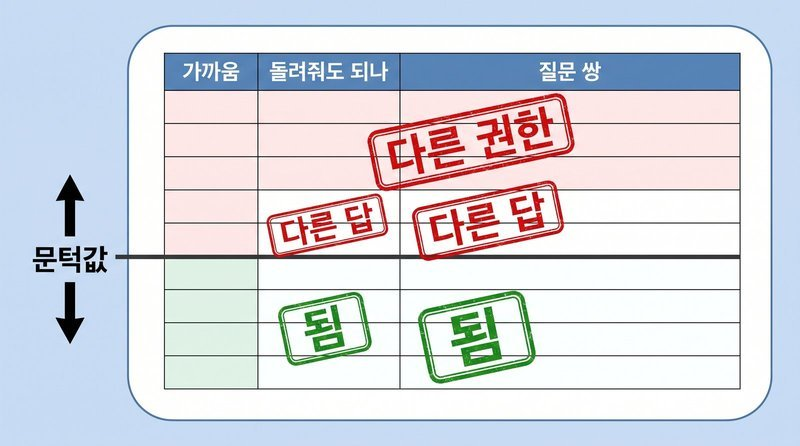

*임계값을 고르는 표에서 붉은 행이 초록 행보다 위에 있으면 시맨틱 캐시는 키부터 다시 설계합니다.*

In [26]:
# 임계값은 바로 앞의 가까움 표를 보고 정합니다
SEM_T = float(os.environ.get("D60_SEM_THRESHOLD", "0.90"))
sem = {}
for scoped in (False, True):
    sem[scoped] = run_set({**BASE_CFG, "answer_cache": AnswerCache("semantic", SEM_T, scoped)},
                          items=TRAFFIC, label="시맨틱(권한)" if scoped else "시맨틱(질문만)")
    cache_report(sem[scoped])
show(plain, r72, sem[False], sem[True])

[시맨틱(질문만)] 질문 18개 
[시맨틱(질문만)] 캐시에서 답함 10/18  틀린 답 9  다른 권한 3
    김공개 재택근무 일주일에 며칠까지 돼요? <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.95))
    정공개 재택근무는 주 며칠까지 가능합니까? <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.97))
    김공개 재택근무 신청은 전날 오후 몇 시까지 해야  <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.94))
    김공개 해외 출장의 1박 숙박비는 최대 몇 만 원입 <- 국내 출장의 1박 숙박비는 최대 몇 만 원입 ('공개',) (캐시(비슷 0.99))
    정공개 자녀 결혼 때 경조 휴가는 며칠입니까? <- 본인 결혼 때 경조 휴가는 며칠입니까 ('공개',) (캐시(비슷 0.98))
    이영업 S 등급은 팀별 상위 몇 퍼센트입니까? <- S 등급은 팀별 상위 몇 퍼센트입니까 ('공개', '인사') (캐시(비슷 1.00))
    김공개 법인카드의 월 한도는 몇 만 원입니까? <- 법인카드의 월 한도는 몇 만 원입니까 ('공개', '재무') (캐시(비슷 1.00))
    김공개 4분기 영업 목표는 3분기 실적의 몇 퍼센트 <- 4분기 영업 목표는 3분기 실적의 몇 퍼센트 ('공개', '영업') (캐시(비슷 1.00))
    김공개 재택근무는 한 주에 최대 며칠까지 신청할 수 <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 1.00))
    이영업 S 등급은 팀별 상위 몇 퍼센트입니까? <- S 등급은 팀별 상위 몇 퍼센트입니까 ('공개', '인사') (캐시(비슷 1.00))
    김공개 법인카드의 월 한도는 몇 만 원입니까? <- 법인카드의 월 한도는 몇 만 원입니까 ('공개', '재무') (캐시(비슷 1.00))
    김공개 4분기 영업 목표는 3분기 실적의 몇 퍼센트 <- 4분기 영업 목표는 

키에 열람 범위를 넣으면 **누출**은 0이 됩니다. **틀린 답**은 키로 막히지 않습니다.

## Step 6. 프리픽스 캐시를 활용하는 프롬프트 순서

이론 노트 3절의 세 규칙을 측정합니다. 같은 요청 목록을 프롬프트 순서 셋으로 실행하고 **캐시 적중 토큰 비율**과 첫 토큰 시간을 비교합니다.

코랩 기준, 아래 코드셀은 완료되기까지 20분 내외가 소요됩니다

In [27]:
def reset_prefix_cache():
    for port, _ in ROUTES.values():
        try:
            requests.post(f"http://127.0.0.1:{port}/reset_prefix_cache", timeout=30)
        except requests.exceptions.RequestException as e:
            print("비우기 실패 :", type(e).__name__)


def cached_ratio(result):
    """캐시 적중 토큰 / 입력 토큰"""
    rows = [r for r in result["rows"] if r["prompt_tokens"]]
    if rows and None not in [r["cached_tokens"] for r in rows]:
        return sum(r["cached_tokens"] for r in rows) / sum(r["prompt_tokens"] for r in rows)


step8 = []
for layout in ["bad", "good-score", "good-id"] if GEN != "local" else []:  # local 은 프리픽스 캐시 없음
    reset_prefix_cache()
    step8.append(run_set({**BASE_CFG, "layout": layout}, items=TRAFFIC, label=layout, warmup=0))
    print("   캐시 적중 토큰 비율 :", cached_ratio(step8[-1]))
show(*step8)

[bad] 질문 18개 
   캐시 적중 토큰 비율 : 0.019320926267935787
[good-score] 질문 18개 
   캐시 적중 토큰 비율 : 0.47127612922087414
[good-id] 질문 18개 
   캐시 적중 토큰 비율 : 0.6162841689811431
bad            임베딩 26/33  검색 4/4  재정렬 3201/3902  조립 0/0  첫 토큰 329/368  나머지 1328/6031  전체 5200/9577  정답 3/18  근거적중 18/18
good-score     임베딩 25/33  검색 3/4  재정렬 3262/3975  조립 0/0  첫 토큰 252/305  나머지 1316/1944  전체 4787/6176  정답 8/18  근거적중 18/18
good-id        임베딩 26/33  검색 3/4  재정렬 3194/3496  조립 0/0  첫 토큰 215/285  나머지 1301/1957  전체 4731/5388  정답 9/18  근거적중 18/18


**눈여겨볼 곳** : `bad`는 request ID가 요청마다 바뀌므로 시스템 메시지 맨 앞부터 어긋나 거의 재사용하지 못합니다. `good-score`는 시스템 메시지만큼 재사용하고 `good-id`는 같은 문서 세트가 다시 들어온 요청에서 문서 부분까지 재사용합니다.

순서는 품질도 바꿀 수 있습니다. 번호 순서가 품질을 떨어뜨리지 않는지 질문 세트로 확인합니다.

In [28]:
by_id = run_set({**BASE_CFG, "layout": "good-id"}, label="번호 순서")
show(baseline, by_id)
print("(flip, 새로 맞힘) :", flips(baseline, by_id))
RESULTS["번호 순서"] = by_id

[번호 순서] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
번호 순서          임베딩 28/33  검색 4/4  재정렬 3284/4118  조립 0/0  첫 토큰 76/206  나머지 1595/3933  전체 5102/7649  정답 13/25  근거적중 25/25
(flip, 새로 맞힘) : (['Q03'], ['Q12', 'Q22', 'Q23'])


## Step 7. 작은 모델과 큰 모델 라우팅

교재 : 1.5.1 LLM 선택 시 고려 사항, 6.11 다중모델 오케스트레이션

질문을 보고 큰 모델로 보낼지 작은 모델로 보낼지 정합니다. 모델 선택 노트 6.2절의 기준대로 **규칙으로 나눌 수 있으면 규칙으로** 나눕니다.

In [29]:
CALC = re.compile(r"(합하면|합해|모두|남은|가운데|\d+박|\d+명)")


def route_of(question):
    return "big" if CALC.search(question) else "small"


print([(x["id"], x["kind"], route_of(x["q"])) for x in QUESTIONS if x["kind"] == "계산" or route_of(x["q"]) == "big"])

[('Q05', '조회', 'big'), ('Q06', '조회', 'big'), ('Q14', '계산', 'big'), ('Q15', '계산', 'big'), ('Q16', '계산', 'big'), ('Q17', '계산', 'big'), ('Q25', '계산', 'small')]


Q25는 계산 질문인데 규칙의 말이 들어 있지 않아 작은 모델로 갑니다. 거꾸로 Q05와 Q06은 조회 질문인데 "1박"이 규칙에 걸려 큰 모델로 갑니다.

`generate`를 다시 만듭니다. 라우팅과 함께 **폴백**을 넣습니다. 큰 모델이 실패하면 작은 모델로 다시 호출하고 둘 다 실패하면 검색한 원문을 화면에 보여 줍니다.

In [30]:
# 실습 : 폴백을 넣은 generate 를 완성하세요
def generate(messages, question, cfg):
    ### START CODE HERE ### (cfg["route"] 가 "auto" 면 route_of 로 경로 고르기 1줄)
    # 1) "auto" 면 질문을 보고 route_of 로 고르고, 아니면 cfg["route"] 를 그대로 씁니다
    route = route_of(question) if cfg["route"] == "auto" else cfg["route"]
    ### END CODE HERE ###
    g = chat_stream(route, messages, cfg["max_tokens"], cfg["chunk_timeout"], cfg["salt"])
    if g["error"] and cfg["fallback"]:
        ### START CODE HERE ### (다른 모델을 고르고 먼저 쓴 시간을 적어 둔 뒤 다시 호출하기 3줄)
        # 1) 먼저 호출한 모델이 아닌 쪽
        other = "small" if route == "big" else "big"
        # 2) 실패한 호출에 이미 쓴 시간
        wasted = g["total_ms"]
        # 3) 다른 모델로 다시 호출합니다. 두 번째 호출에는 첫 토큰 상한을 걸지 않습니다(None)
        g2 = chat_stream(other, messages, cfg["max_tokens"], None, cfg["salt"])
        ### END CODE HERE ###
        g2["route"] = f"{route}→{other}"
        g2["first_error"] = g["error"]
        g2["total_ms"] += wasted
        if g2["ttft_ms"] is not None:
            g2["ttft_ms"] += wasted
        g = g2
    if g["error"]:
        docs = messages[1]["content"].split("\n\n문의한 직원")[0]
        g["text"] = "답 : 생성 서버가 응답하지 않아 답을 만들지 못했습니다\n근거 원문 :\n" + docs
        g["route"] += "→원문"
    return g

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
# 1) 라우팅
route = route_of(question) if cfg["route"] == "auto" else cfg["route"]

# 2) 폴백
other = "small" if route == "big" else "big"
wasted = g["total_ms"]
g2 = chat_stream(other, messages, cfg["max_tokens"], None, cfg["salt"])
```

두 번째 호출에는 `chunk_timeout`을 걸지 않았습니다. 폴백까지 시간 상한으로 끊으면 사용자는 아무 답도 받지 못합니다.

</details>

In [31]:
def by_kind(result):
    ok = Counter(QMAP[r["qid"]]["kind"] for r in result["rows"] if r["ok"])
    n = Counter(QMAP[r["qid"]]["kind"] for r in result["rows"])
    return "  ".join(f"{k} {ok[k]}/{n[k]}" for k in n) + f"  경로 {dict(Counter(x['route'] for x in result['rows']))}"


small_all = run_set({**BASE_CFG, "route": "small"}, label="전부 작은 모델")
auto = run_set({**BASE_CFG, "route": "auto"}, label="라우팅")
show(baseline, small_all, auto)
for r in (baseline, small_all, auto):
    print(f"  {r['label']:10} {by_kind(r)}")
print("라우팅의 (flip, 새로 맞힘) :", flips(baseline, auto))
RESULTS["라우팅"] = auto

[전부 작은 모델] 질문 25개 
[라우팅] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
전부 작은 모델       임베딩 28/34  검색 4/4  재정렬 3313/4076  조립 0/0  첫 토큰 124/139  나머지 1762/3396  전체 5495/7440  정답 15/25  근거적중 25/25
라우팅            임베딩 28/34  검색 4/4  재정렬 3278/4000  조립 0/0  첫 토큰 64/227  나머지 1584/4865  전체 5367/8592  정답 14/25  근거적중 25/25
  기준선        조회 8/14  계산 1/5  권한 2/6  경로 {'big': 25}
  전부 작은 모델   조회 12/14  계산 2/5  권한 1/6  경로 {'small': 25}
  라우팅        조회 12/14  계산 1/5  권한 1/6  경로 {'small': 19, 'big': 6}
라우팅의 (flip, 새로 맞힘) : (['Q10', 'Q18'], ['Q01', 'Q02', 'Q04', 'Q07', 'Q12'])


## Step 8. 선택 심화 트랙

트랙을 **하나 이상 골라** 수행하고 공유합니다. 트랙 1은 Step 4, 트랙 2는 Step 5의 결과를 씁니다. 후보 수 곡선, 동시 요청 수, 프리픽스 캐시와 솔트, 시맨틱 캐시 임계값 곡선은 노트 끝 부록 실습 D\~F와 J에 있습니다.

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | 문장 선택으로 하는 컨텍스트 축소 | 최적화 | 상 |
| 2 | 시맨틱 캐시 임계값 | 위험 | 중 |

#### 트랙 1. 문장 선택으로 하는 컨텍스트 축소

청크마다 질문과 글자가 많이 겹치는 문장 두 개만 남기는 압축을 붙입니다.

In [32]:
def grams(text):
    t = "".join(text.split())
    return {t[i:i + 2] for i in range(len(t) - 1)}


def compress(ctx, question, keep=2):
    """질문과 많이 겹치는 문장 keep 개만 남깁니다"""
    out = []
    for d in ctx:
        sents = [x for x in re.split(r"(?<=다\.)\s+", d["본문"]) if x.strip()]
        top = sorted(sorted(range(len(sents)), key=lambda i: -len(grams(question) & grams(sents[i])))[:keep])
        out.append({**d, "본문": " ".join(sents[i] for i in top)})
    return out


_build_original = build_messages              # 잠시 바꿨다가 되돌립니다
build_messages = lambda q, u, ctx, layout="good-score": _build_original(q, u, compress(ctx, q), layout)
try:
    squeezed = run_set(BASE_CFG, label="문장 압축")
finally:
    build_messages = _build_original
show(baseline, squeezed)
print(f"입력 토큰 {avg_prompt(baseline):.0f} -> {avg_prompt(squeezed):.0f} / (flip, 새로 맞힘) {flips(baseline, squeezed)}")
print("Q15 의 반차 문서 :", compress(DOCS[3:4], QMAP["Q15"]["q"])[0]["본문"])

[문장 압축] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
문장 압축          임베딩 25/33  검색 4/4  재정렬 3228/3852  조립 0/0  첫 토큰 205/219  나머지 1673/3336  전체 5315/6660  정답 7/25  근거적중 25/25
입력 토큰 741 -> 652 / (flip, 새로 맞힘) (['Q08', 'Q10', 'Q24', 'Q25'], [])
Q15 의 반차 문서 : 반차는 하루 근무 시간의 절반인 4시간으로 계산하며 연차 0.5일을 쓴 것으로 본다. 오전 반차는 오후 2시에 출근하고 오후 반차는 오후 1시에 퇴근한다.


#### 트랙 2. 시맨틱 캐시 임계값

Step 5의 가까움 표에서 "됨"과 "다른 답"이 섞이는 구간의 아래와 위에서 임계값을 하나씩 골라 실제로 실행합니다. 임계값을 낮추면 캐시에서 답하는 요청이 늘면서 틀린 답도 함께 늡니다. 이 비교를 **여러분이 고른 임베딩 모델로** 다시 하기 전에는 남이 쓴 임계값을 가져오지 않습니다.

In [33]:
# 가까움 표를 보고 두 임계값을 고릅니다. 환경 변수가 없으면 0.85, 0.95
for t in [float(x) for x in os.environ.get("D60_SEM_PAIR", "0.85,0.95").split(",")]:
    cache_report(run_set({**BASE_CFG, "answer_cache": AnswerCache("semantic", t, scoped=True)},
                         items=TRAFFIC, label=f"시맨틱 {t}", warmup=0))

[시맨틱 0.85] 질문 18개 
[시맨틱 0.85] 캐시에서 답함 7/18  틀린 답 7  다른 권한 0
    김공개 재택근무 일주일에 며칠까지 돼요? <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.95))
    정공개 재택근무는 주 며칠까지 가능합니까? <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.97))
    김공개 재택근무 신청은 전날 오후 몇 시까지 해야  <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.94))
    김공개 1년 이상 근무한 직원의 연차는 1년에 며칠 <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 0.86))
    김공개 해외 출장의 1박 숙박비는 최대 몇 만 원입 <- 국내 출장의 1박 숙박비는 최대 몇 만 원입 ('공개',) (캐시(비슷 0.99))
    정공개 자녀 결혼 때 경조 휴가는 며칠입니까? <- 본인 결혼 때 경조 휴가는 며칠입니까 ('공개',) (캐시(비슷 0.98))
    김공개 재택근무는 한 주에 최대 며칠까지 신청할 수 <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 1.00))
[시맨틱 0.95] 질문 18개 
[시맨틱 0.95] 캐시에서 답함 5/18  틀린 답 4  다른 권한 0
    정공개 재택근무는 주 며칠까지 가능합니까? <- 재택근무 일주일에 며칠까지 돼요 ('공개',) (캐시(비슷 0.97))
    김공개 해외 출장의 1박 숙박비는 최대 몇 만 원입 <- 국내 출장의 1박 숙박비는 최대 몇 만 원입 ('공개',) (캐시(비슷 0.99))
    정공개 자녀 결혼 때 경조 휴가는 며칠입니까? <- 본인 결혼 때 경조 휴가는 며칠입니까 ('공개',) (캐시(비슷 0.98))
    김공개 재택근무는 한 주에 최대 며칠까지 신청할 수 <- 재택근무는 한 주에 최대 며칠까지 신청할 수 ('공개',) (캐시(비슷 1.00))


## Step 9. 공유와 정리

교재 : 3.4.3 애플리케이션에 가장 적합한 모델 선택하기

먼저 flip 없이 시간을 줄인 설정만 모아 한 번 더 측정하고 결과 파일을 남깁니다. MLOps 소개 노트가 이 파일의 `기준선`과 `고른 설정`을 읽으므로 파일 이름과 키를 바꾸지 않습니다.

아래 코드셀은 위에서 실행한 결과를 반영하지 않는다면 수행되지 않습니다.

In [35]:
# Step 4, 6, 7 결과를 보고 고치세요. flip이 나온 설정은 넣지 않습니다
CHOSEN = {**BASE_CFG, "max_tokens": 120}
final = run_set(CHOSEN, label="고른 설정")
show(baseline, final)
print("(flip, 새로 맞힘) :", flips(baseline, final))
lost,_=flips(baseline,final)
if any(r.get("error") for r in baseline["rows"]):
    raise RuntimeError("기준선 요청이 실패해 선택 근거가 유효하지 않습니다.")
if lost or any(r.get("error") for r in final["rows"]):
    raise RuntimeError("바뀐 설정에 잃은 정답이나 요청 실패가 있습니다. 고른 설정으로 저장하지 않습니다.")
RESULTS["고른 설정"] = final

[고른 설정] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
고른 설정          임베딩 27/34  검색 4/4  재정렬 3344/4230  조립 0/0  첫 토큰 75/262  나머지 1533/3529  전체 5265/7121  정답 11/25  근거적중 25/25
(flip, 새로 맞힘) : ([], [])


측정값 옆에는 언제나 어떤 모드(진짜 모델인지 mock인지)로 측정한 것인지가 같이 있어야 합니다.

In [36]:
def pack(r):
    return {"cfg": r["cfg"], "summary": r["summary"], "flips": flips(baseline, r)[0] if r["summary"] else None,
            "rows": [{k: v for k, v in x.items() if k != "answer"} for x in r["rows"]]}


meta = {"gen": GEN, "embedding": EMB_NAME, "reranker": RERANK_NAME, "standin": STANDIN, "big": BIG_ID, "small": SMALL_ID,
        "gpu": torch.cuda.get_device_name(0) if HAS_GPU else None, "questions": len(QUESTIONS), "date": time.strftime("%Y-%m-%d")}
out_path = WORK / "d60_results.json"
out_path.write_text(json.dumps({"meta": meta, "runs": {k: pack(v) for k, v in RESULTS.items()}},
                               ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("저장 :", out_path, list(RESULTS), meta["gen"], meta["standin"])

저장 : /content/d60/d60_results.json ['기준선', '청크 3개', '답 상한 120', '둘 다', '번호 순서', '라우팅', '고른 설정'] vllm False


각자 수행한 트랙과 본 실습 결과를 공유합니다.

**1. 기준선의 구간표** : 가장 큰 구간과 두 번째 구간, 첫 토큰 구간과 디코드 구간의 비율

**2. 설정마다 줄어든 구간과 flip** : 남긴 설정과 뺀 설정, 뺀 이유

**3. 캐시** : Step 5 가까움 표에서 "됨"과 "다른 답"이 섞인 지점, 키에 넣은 필드

**4. 해커톤 예산표에 옮길 수치** : 고른 설정의 구간별 중앙값과 p95, 어느 모드로 측정한 수치인지

반복 원칙을 다시 확인했습니다. **싼 것으로 좁히고 비싼 것으로 확인합니다.**

부록 실습을 하지 않고 끝낼 때도 노트 맨 끝 부록 실습 K의 셀로 서버를 모두 종료합니다.

### 혼자 설명하기

답변 캐시를 켠 뒤 빨라졌지만, 문서가 바뀌었거나 사용자 권한이 다른 질문에서 문제가 생겼습니다. 단계별 처리 시간, 검색한 문서, 실제 답을 비교해 유지할 설정과 수정할 설정을 설명합니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D61\~65는 해커톤 기간입니다. D66에서는 보관한 실험 결과에 모델·질문·설정을 함께 기록해 다른 사람이 확인하고 재실행할 수 있게 만듭니다.

## 마무리 과제. RAG 서빙 최적화 보고서

여러분의 해커톤 주제나 오늘의 사내 규정 서비스로 한 장짜리 보고서를 씁니다.

**1단계. 기준선**

1. 질문 세트를 정하고 개수를 적습니다  
2. 기준선의 구간표를 중앙값과 p95로 적고 어느 모드(진짜 모델, mock)로 측정한 것인지 밝힙니다

**2단계. 줄이기**

3. 가장 큰 구간부터 설정을 셋 이상 하나씩 바꿉니다. 설정마다 줄어든 구간과 flip을 적습니다  
4. 라우팅 규칙을 고쳐 Q25를 큰 모델로 보내고 그 대가(큰 모델로 더 간 질문 수와 시간)를 적습니다  
5. flip이 나온 설정은 빼고 고른 조합을 다시 측정합니다

**3단계. 캐시 판단서**

6. 시맨틱 캐시를 쓸지 정합니다. 임계값 표, 키에 넣을 필드, 저장하지 않을 답, 문서가 바뀔 때 지우는 방법을 적습니다  
7. 쓰지 않기로 했다면 그 이유를 수치로 적습니다

**4단계. 예산표**

8. 시스템 디자인 노트의 설계 문서 예산표 항목을 오늘의 실측으로 채웁니다

**평가 기준**

- 측정값마다 어느 모드와 어느 GPU로 측정한 것인지 적혀 있는가  
- 설정을 한 번에 하나씩 바꿨는가  
- 설정마다 같은 질문 세트로 flip을 셌는가  
- 쓰지 않기로 한 설정과 그 이유가 적혀 있는가

## 부록 실습 A. GPU나 허브 없이 실행하기

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 부록 실습 B부터는 본 실습 Step 9까지 실행한 상태에서 시작합니다.

부록 실습 A만 예외입니다. GPU가 없거나(`D60_GEN=fake`), vLLM 없이 transformers로 생성하거나(`D60_GEN=local`), 허브에 연결되지 못해 mock 검색 모델을 써야 할 때 **본 실습 Step 1의 요청 목록(`TRAFFIC`) 셀 다음, "검색 단계" 앞에서** 이 셀들을 실행하고 Step 1로 돌아갑니다. local 모드의 마지막 셀만 Step 2 다음에 실행합니다. GPU와 허브가 있는 코랩에서는 건너뜁니다.

허브에 연결되지 못할 때 쓰는 mock 임베딩과 mock 재정렬입니다. 진짜 모델과 호출하는 형식만 같고 측정값은 진짜 모델의 것이 아닙니다.

mock 서버는 `fake` 모드에서만 씁니다. 정답표를 들고 있다가 **근거 문서가 프롬프트에 모두 들어 있을 때만** 맞히고 작은 모델 역할이면 계산 질문을 틀립니다.

In [37]:
%%writefile fake_llm_server.py
"""mock 생성 서버. OpenAI 호환 /v1/chat/completions 와 vLLM 의 몇 가지 주소를 재현합니다.

시간은 실측이 아니라 설정값입니다.
- 첫 토큰 : (입력 토큰 - 캐시 적중 토큰) x PREFILL_MS + BASE_MS
- 디코드   : 토큰마다 DECODE_MS
- 프리픽스 캐시 : 16토큰 블록마다 앞 블록의 해시를 이어 붙인 해시 체인. 처음 어긋난 블록부터 다시 계산
답은 정답표(D60_FAKE_KEY)를 보고 정합니다
"""
import asyncio
import hashlib
import json
import os
import re
import time
import uuid
from collections import OrderedDict

from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse, PlainTextResponse, StreamingResponse

ROLE = os.environ.get("D60_FAKE_ROLE", "big")
SPEED = float(os.environ.get("D60_FAKE_SPEED", "1.0"))        # 1보다 작으면 빨라집니다
PREFILL_MS = float(os.environ.get("D60_FAKE_PREFILL_MS", "0.25" if ROLE == "big" else "0.08"))
DECODE_MS = float(os.environ.get("D60_FAKE_DECODE_MS", "25" if ROLE == "big" else "9"))
BASE_MS = 30.0 if ROLE == "big" else 15.0
SLOTS = int(os.environ.get("D60_FAKE_SLOTS", "4"))
MODEL = os.environ.get("D60_FAKE_MODEL", f"fake-{ROLE}")
BLOCK = 16
KEY = json.loads(open(os.environ["D60_FAKE_KEY"], encoding="utf-8").read())
DOC_RE = re.compile(r"\[문서 ([가-힣]+-\d+) · 버전 (\d+)\][^\n]*\n([^\n]+)")

app = FastAPI()
slots = asyncio.Semaphore(SLOTS)
CACHE = OrderedDict()
STATS = {"queries": 0, "hits": 0}


def tokens(text):
    return [text[i:i + 2] for i in range(0, len(text), 2)]      # 두 글자를 토큰 하나로 칩니다


def render(messages):
    body = "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in messages)
    return body + "<|im_start|>assistant\n"


def prefix_cached(toks, salt):
    """앞에서부터 이어지는 블록 중 캐시에 있는 만큼을 셉니다. 한 번 어긋나면 그 뒤는 못 씁니다"""
    h, hit, missed = hashlib.sha256((salt or "").encode()).hexdigest(), 0, False
    for b in range(len(toks) // BLOCK):
        h = hashlib.sha256((h + "".join(toks[b * BLOCK:(b + 1) * BLOCK])).encode()).hexdigest()
        if not missed and h in CACHE:
            CACHE.move_to_end(h)
            hit += 1
        else:
            missed = True
            CACHE[h] = True
            if len(CACHE) > 50000:
                CACHE.popitem(last=False)
    return min(hit * BLOCK, max(len(toks) - 1, 0))


def fmt(x):
    return str(int(x)) if float(x).is_integer() else str(x)


def decide(prompt):
    asks = re.findall(r"질문 : ([^\n]+)", prompt)
    info = KEY.get(asks[-1].split("<|im_end|>")[0].strip()) if asks else None
    present = {d: (int(r), body) for d, r, body in DOC_RE.findall(prompt)}
    if not info or not info["근거"] or not all(b in present for b in info["근거"]):
        return "답 : 근거를 찾지 못했습니다\n근거 : 없음\n설명 : 열람할 수 있는 문서에서 이 질문의 근거를 찾지 못했습니다."
    ans = info["answer"]
    for b, revs in info.get("rev", {}).items():
        if b in present and str(present[b][0]) in revs:
            ans = revs[str(present[b][0])]
    if ROLE == "small" and info["kind"] == "계산":
        nums = re.findall(r"\d+(?:\.\d+)?", present[info["근거"][0]][1])
        ans = float(nums[0]) if nums else -1          # 작은 모델 역할 : 첫 숫자를 그대로 읽는 실수
    why = present[info["근거"][0]][1]
    return f"답 : {fmt(ans)}\n근거 : {', '.join(info['근거'])}\n설명 : {why}"


@app.get("/health")
def health():
    return {"status": "ok", "role": ROLE}


@app.get("/v1/models")
def models():
    return {"object": "list", "data": [{"id": MODEL, "object": "model"}]}


@app.get("/metrics")
def metrics():
    lab = f'{{model_name="{MODEL}"}}'
    return PlainTextResponse(f"vllm:prefix_cache_queries_total{lab} {STATS['queries']}\n"
                             f"vllm:prefix_cache_hits_total{lab} {STATS['hits']}\n")


@app.post("/reset_prefix_cache")
def reset():
    CACHE.clear()
    return {"ok": True}


@app.post("/v1/chat/completions")
async def chat(req: Request):
    body = await req.json()
    prompt = render(body["messages"])
    toks = tokens(prompt)
    max_tokens = int(body.get("max_tokens") or 512)
    queued = time.perf_counter()
    rid = f"chatcmpl-{uuid.uuid4().hex[:12]}"

    async def run():
        async with slots:
            start = time.perf_counter()
            cached = prefix_cached(toks, body.get("cache_salt"))
            STATS["queries"] += len(toks)
            STATS["hits"] += cached
            await asyncio.sleep(((len(toks) - cached) * PREFILL_MS + BASE_MS) * SPEED / 1000)
            first = time.perf_counter()
            out = tokens(decide(prompt))[:max_tokens]
            for i, t in enumerate(out):
                if i:
                    await asyncio.sleep(DECODE_MS * SPEED / 1000)
                yield t
            end = time.perf_counter()
            run.info = {"cached": cached, "n": len(out), "queue": start - queued,
                        "ttft": first - queued, "gen": end - first,
                        "finish": "length" if len(out) == max_tokens else "stop"}

    def usage_and_metrics():
        i = run.info
        return ({"prompt_tokens": len(toks), "completion_tokens": i["n"],
                 "total_tokens": len(toks) + i["n"],
                 "prompt_tokens_details": {"cached_tokens": i["cached"]}},
                {"time_to_first_token_ms": round(i["ttft"] * 1000, 1),
                 "queue_time_ms": round(i["queue"] * 1000, 1),
                 "generation_time_ms": round(i["gen"] * 1000, 1),
                 "mean_itl_ms": round(i["gen"] * 1000 / max(i["n"] - 1, 1), 2),
                 "tokens_per_second": round(i["n"] / max(i["gen"], 1e-6), 1)})

    if not body.get("stream"):
        text = "".join([t async for t in run()])
        usage, mets = usage_and_metrics()
        return JSONResponse({"id": rid, "object": "chat.completion", "created": int(time.time()),
                             "model": MODEL, "usage": usage, "metrics": mets,
                             "choices": [{"index": 0, "finish_reason": run.info["finish"],
                                          "message": {"role": "assistant", "content": text}}]})

    async def sse():
        def chunk(delta, finish=None):
            return {"id": rid, "object": "chat.completion.chunk", "created": int(time.time()),
                    "model": MODEL, "choices": [{"index": 0, "delta": delta, "finish_reason": finish}]}
        yield f"data: {json.dumps(chunk({'role': 'assistant', 'content': ''}), ensure_ascii=False)}\n\n"
        async for t in run():
            yield f"data: {json.dumps(chunk({'content': t}), ensure_ascii=False)}\n\n"
        yield f"data: {json.dumps(chunk({}, run.info['finish']), ensure_ascii=False)}\n\n"
        if (body.get("stream_options") or {}).get("include_usage"):
            usage, mets = usage_and_metrics()
            last = {"id": rid, "object": "chat.completion.chunk", "created": int(time.time()),
                    "model": MODEL, "choices": [], "usage": usage, "metrics": mets}
            yield f"data: {json.dumps(last, ensure_ascii=False)}\n\n"
        yield "data: [DONE]\n\n"

    return StreamingResponse(sse(), media_type="text/event-stream")

Writing fake_llm_server.py


In [38]:
KEY = {}
for x in QUESTIONS:
    if x["q"] in KEY and not x["근거"]:      # 같은 글자의 권한 질문은 근거가 있는 쪽을 남깁니다
        continue
    KEY[x["q"]] = {"answer": x["answer"], "근거": x["근거"], "kind": x["kind"]}
for user, text, qid in TRAFFIC:
    KEY[text] = dict(KEY[QMAP[qid]["q"]])
KEY[QMAP["Q01"]["q"]]["rev"] = {"공개-02": {"2": 3}}       # Step 5 : 주 2일 -> 주 3일
for user, text, qid in TRAFFIC:
    if qid == "Q01":
        KEY[text]["rev"] = {"공개-02": {"2": 3}}
(WORK / "fake_key.json").write_text(json.dumps(KEY, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"정답표 {len(KEY)}건 저장 (mock 서버만 읽습니다)")

정답표 25건 저장 (mock 서버만 읽습니다)


`local` 모드는 vLLM 서버 대신 노트 안에서 transformers로 직접 생성합니다. 프리픽스 캐시가 없으므로 Step 6의 측정은 건너뜁니다. 이 셀은 모델을 로드하고, 다음 셀은 Step 2를 실행한 뒤에 실행합니다.

In [39]:
import threading

LOCAL = {}
if GEN == "local":
    !pip install -q "bitsandbytes>=0.50,<0.51"
    from transformers import (AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig,
                              GenerationConfig)
    plan = {"big": (os.environ.get("D60_LOCAL_BIG_ID", "Qwen/Qwen2.5-7B-Instruct"), True),
            "small": (os.environ.get("D60_LOCAL_SMALL_ID", "Qwen/Qwen2.5-1.5B-Instruct"), False)}
    for role, (mid, four_bit) in plan.items():
        tok = AutoTokenizer.from_pretrained(mid)
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_compute_dtype=torch.float16) if four_bit else None
        model = AutoModelForCausalLM.from_pretrained(mid, dtype=torch.float16, quantization_config=bnb,
                                                     device_map={"": 0} if HAS_GPU else "cpu")
        LOCAL[role] = (tok, model.eval(), mid)
        print(f"[{role}] {mid} 로드 완료")


def _local_stream(route, messages, max_tokens, t0):
    out = {"ttft_ms": None}
    from transformers import GenerationConfig, TextIteratorStreamer

    tok, model, _ = LOCAL[route]
    text = tok.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    ids = tok(text, return_tensors="pt").to(model.device)
    out["prompt_tokens"] = int(ids["input_ids"].shape[1])
    streamer = TextIteratorStreamer(tok, skip_prompt=True, skip_special_tokens=True, timeout=30)
    # 저장소의 생성 설정이 섞이지 않게 새 설정을 통째로 씌웁니다 (GPTQ·AWQ 노트의 함정)
    cfg = GenerationConfig(max_new_tokens=max_tokens, do_sample=False,
                           eos_token_id=model.generation_config.eos_token_id,
                           pad_token_id=tok.pad_token_id or tok.eos_token_id)
    from transformers import StoppingCriteria, StoppingCriteriaList
    stop=threading.Event();errors=[]
    class StopOnRequest(StoppingCriteria):
        def __call__(self,input_ids,scores,**kwargs):
            return torch.full((input_ids.shape[0],),stop.is_set(),device=input_ids.device,dtype=torch.bool)
    def worker():
        try:
            with torch.inference_mode():
                model.generate(**ids,streamer=streamer,generation_config=cfg,
                    stopping_criteria=StoppingCriteriaList([StopOnRequest()]))
        except Exception as exc:errors.append(exc)
        finally:streamer.end()
    th=threading.Thread(target=worker,daemon=True);th.start()
    parts=[]
    try:
        for piece in streamer:
            if piece and out["ttft_ms"] is None:out["ttft_ms"]=(time.perf_counter()-t0)*1000
            parts.append(piece)
    finally:
        stop.set();th.join(timeout=60)
    if th.is_alive():raise RuntimeError("생성 작업이 끝나지 않았습니다. 다음 요청을 실행하지 마세요.")
    if errors:raise errors[0]
    out["text"] = "".join(parts)
    return out


print("local 모드 모델 :", list(LOCAL) or "없음 (D60_GEN=local 이 아닙니다)")

local 모드 모델 : 없음 (D60_GEN=local 이 아닙니다)


`local` 모드에서는 **본 실습 Step 2를 실행한 다음** 이 셀을 실행합니다. Step 2의 `chat_stream`을 로드한 모델로 생성하는 함수로 바꿉니다.

In [40]:
_chat_stream_server = chat_stream


def chat_stream(route, messages, max_tokens, chunk_timeout=None, salt=None):
    """local 모드 : 서버 대신 노트 안의 모델로 생성합니다. 반환 필드는 Step 2 의 chat_stream 과 같습니다"""
    if GEN != "local":
        return _chat_stream_server(route, messages, max_tokens, chunk_timeout, salt)
    out = dict(route=route, text="", ttft_ms=None, rest_ms=None, total_ms=None,
               prompt_tokens=None, cached_tokens=None, server=None, error=None)
    t0 = time.perf_counter()
    try:
        out.update(_local_stream(route, messages, max_tokens, t0))
    except Exception as e:
        out["error"] = type(e).__name__
    out["total_ms"] = (time.perf_counter() - t0) * 1000
    if out["ttft_ms"]:
        out["rest_ms"] = out["total_ms"] - out["ttft_ms"]
    return out


print(chat_stream("big", [{"role": "user", "content": "한국어 한 문장으로 인사하세요."}], 40)["text"][:60])

안녕하세요! 저는 한국어로 인사를 드리겠습니다. 어떻게 도와드릴까요?


## 부록 실습 B. 클라이언트·서버에서 잰 처리 시간 비교

이론 노트 1.4절과 3.1절을 확인하는 실습입니다. 클라이언트가 요청을 보낸 뒤 첫 텍스트를 받은 시간과 서버가 첫 토큰을 생성하기까지의 시간을 비교합니다. 서버 `/metrics`에서는 입력 앞부분의 캐시를 조회한 토큰 수와 재사용한 토큰 수를 확인합니다.

부록 실습 B\~K가 쓰는 서버 점검 함수입니다. 부록 실습을 시작할 때 이 셀을 먼저 실행합니다.

In [41]:
def ensure_qdrant():
    """Qdrant 가 종료되었으면 다시 기동합니다"""
    try:
        qc.get_collections()
    except Exception:
        print("[qdrant] 서버가 종료되어 있어 다시 기동합니다")
        start_qdrant()


def ensure_llm():
    """생성 서버가 종료되었으면 mock 서버는 다시 기동하고 vLLM 서버는 안내만 출력합니다"""
    for role, (port, model_id) in ROUTES.items():
        if role not in LLM_PROCS:                    # local 모드는 서버를 기동하지 않습니다
            continue
        try:
            if requests.get(f"http://127.0.0.1:{port}/health", timeout=3).status_code == 200:
                continue
        except requests.exceptions.RequestException:
            pass
        if GEN == "fake":
            LLM_PROCS[role] = start_llm(role, model_id, port)
        else:
            print(f"[{role}] 서버가 종료되어 있습니다. Step 2 의 기동 셀을 다시 실행하세요")


ensure_qdrant()
ensure_llm()

설치된 버전을 기록해 둡니다. 결과가 달라졌을 때 가장 먼저 볼 기록입니다.

In [42]:
# 설치된 버전을 기록해 둡니다. 결과가 달라졌을 때 가장 먼저 볼 기록입니다
from importlib.metadata import version, PackageNotFoundError

for name in ["torch", "transformers", "sentence-transformers", "qdrant-client", "openai", "vllm"]:
    try:
        print(f"{name:22} {version(name)}")
    except PackageNotFoundError:
        print(f"{name:22} (설치되지 않음)")

torch                  2.13.0
transformers           5.22.1
sentence-transformers  6.3.0
qdrant-client          1.20.0
openai                 3.51.0
vllm                   0.30.0


기준선에서 구간마다 평균이 전체의 몇 퍼센트인지 출력합니다(이론 노트 1.5절의 "가장 큰 구간부터").

In [43]:
def shares(result):
    rows = [r for r in result["rows"] if r["spans"]]
    mean = {n: np.mean([r["spans"].get(n, 0.0) for r in rows]) for n in SEGMENTS}
    total = sum(mean.values())
    for n in SEGMENTS:
        if mean[n] > 0:
            print(f"  {n:6} {mean[n]:9.1f} ms  {mean[n] / total:6.1%}  " + "#" * int(40 * mean[n] / total))
    prompt = [r["prompt_tokens"] for r in rows if r["prompt_tokens"]]
    if prompt:
        print(f"  입력 토큰 평균 {np.mean(prompt):.0f}개")


shares(baseline)

  임베딩         28.0 ms    0.5%  
  검색           3.8 ms    0.1%  
  재정렬       3228.8 ms   60.8%  ########################
  조립           0.0 ms    0.0%  
  첫 토큰       222.3 ms    4.2%  #
  나머지       1828.7 ms   34.4%  #############
  입력 토큰 평균 741개


In [44]:
# 클라이언트가 측정한 첫 토큰과 서버가 측정한 첫 토큰의 차이를 봅니다.
# server 필드는 vLLM 의 --enable-per-request-metrics 와 mock 서버에만 있습니다
gap = []
for user, text, qid in [(x["user"], x["q"], x["id"]) for x in QUESTIONS[:6]]:
    msgs = build_messages(text, user, rerank(text, search(embed([text], "query")[0], USERS[user]))[:5])
    g = chat_stream("big", msgs, 60)
    if g["server"] and g["ttft_ms"] is not None:
        gap.append(g["ttft_ms"] - g["server"]["time_to_first_token_ms"])
if gap:
    print(f"클라이언트 첫 토큰 - 서버 첫 토큰 : 평균 {np.mean(gap):.1f} ms (연결, 전송, 응답을 읽는 시간)")
else:
    print("서버가 측정한 시간이 없습니다. local 모드이거나 서버 옵션이 꺼져 있습니다")

클라이언트 첫 토큰 - 서버 첫 토큰 : 평균 10.5 ms (연결, 전송, 응답을 읽는 시간)


In [45]:
def prefix_counters(port):
    try:
        text = requests.get(f"http://127.0.0.1:{port}/metrics", timeout=10).text
    except requests.exceptions.RequestException:
        return None
    def total(name):
        return sum(float(v) for v in re.findall(rf"^{name}(?:_total)?{{[^}}]*}} ([0-9.eE+]+)$", text, re.M))
    return total("vllm:prefix_cache_queries"), total("vllm:prefix_cache_hits")


c = prefix_counters(BIG_PORT)
if c:
    print(f"큰 모델 서버 누적 : 조회 {c[0]:.0f}토큰, 캐시 적중 {c[1]:.0f}토큰 ({c[1] / max(c[0], 1):.1%})")
else:
    print("/metrics 를 읽지 못했습니다")

큰 모델 서버 누적 : 조회 252642토큰, 캐시 적중 191024토큰 (75.6%)


## 부록 실습 C. 서로 기다릴 필요가 없는 작업의 동시 실행

교재 : 4.5.1 벡터 데이터베이스, 6.12.1 비동기 쿼리 처리, 6.12.2 밀집 검색과 희소 검색 방법 결합

프라이빗 RAG 노트 트랙 2의 하이브리드 검색(벡터 검색과 BM25를 RRF로 합치기)을 붙이고 권한 조회와 대화 기록 불러오기를 진짜 사내 시스템처럼 시간이 걸리는 호출로 바꿉니다. 그다음 **서로를 기다리지 않아도 되는 일**을 동시에 실행합니다.

In [46]:
from concurrent.futures import ThreadPoolExecutor

from rank_bm25 import BM25Okapi


def tokenize_ko(text):
    """프라이빗 RAG 노트 트랙 2와 같은 토크나이저입니다"""
    return re.findall(r"[가-힣]+|[A-Za-z]+|[0-9]+", text) + re.findall(r"제\d+조", text)


bm25 = BM25Okapi([tokenize_ko(d["제목"] + " " + d["본문"]) for d in DOCS])
PERM_DELAY = float(os.environ.get("D60_PERM_DELAY", "0.04"))     # mock : 사내 인사 시스템 조회 40ms
HISTORY_DELAY = float(os.environ.get("D60_HISTORY_DELAY", "0.03"))  # mock : 대화 기록 저장소 조회 30ms
POOL = ThreadPoolExecutor(max_workers=4)


def lookup_permissions(user):
    time.sleep(PERM_DELAY)
    return USERS[user]


def load_history(user):
    time.sleep(HISTORY_DELAY)
    return []                     # 오늘은 대화 기록을 프롬프트에 넣지 않습니다. 기다리는 시간만 재현합니다


def bm25_search(question, depts, limit=20):
    """점수를 매긴 뒤 볼 수 없는 문서를 지우고 나서 상위를 자릅니다. 순서가 바뀌면 누출됩니다"""
    scores = bm25.get_scores(tokenize_ko(question))
    order = [i for i in np.argsort(-scores) if DOCS[i]["부서"] in depts and scores[i] > 0]
    return [dict(DOCS[i], score=float(scores[i])) for i in order[:limit]]


def rrf(*rankings, k=60):
    fused = {}
    for ranking in rankings:
        for rank, d in enumerate(ranking):
            item = fused.setdefault(d["id"], {**d, "rrf": 0.0})
            item["rrf"] += 1.0 / (k + rank + 1)
    return sorted(fused.values(), key=lambda d: -d["rrf"])


def retrieve_hybrid(question, user, parallel):
    rec = Spans()
    if parallel:
        with rec.span("임베딩과 조회"):
            f_vec = POOL.submit(embed, [question], "query")
            f_perm = POOL.submit(lookup_permissions, user)
            f_hist = POOL.submit(load_history, user)
            qvec, depts, history = f_vec.result()[0], f_perm.result(), f_hist.result()
        with rec.span("두 검색"):
            f_dense = POOL.submit(search, qvec, depts, 20)
            f_sparse = POOL.submit(bm25_search, question, depts, 20)
            dense, sparse = f_dense.result(), f_sparse.result()
    else:
        with rec.span("임베딩과 조회"):
            depts = lookup_permissions(user)
            history = load_history(user)
            qvec = embed([question], "query")[0]
        with rec.span("두 검색"):
            dense = search(qvec, depts, 20)
            sparse = bm25_search(question, depts, 20)
    with rec.span("합치기"):
        fused = rrf(dense, sparse)
    return fused, rec.ms


for parallel in (False, True):
    spans = [retrieve_hybrid(x["q"], x["user"], parallel)[1] for x in QUESTIONS]
    mean = {k: np.mean([s[k] for s in spans]) for k in spans[0]}
    print(f"{'동시에' if parallel else '차례로'} : " + "  ".join(f"{k} {v:6.1f}ms" for k, v in mean.items())
          + f"  / 합 {sum(mean.values()):6.1f}ms")

차례로 : 임베딩과 조회   99.8ms  두 검색    3.8ms  합치기    0.0ms  / 합  103.6ms
동시에 : 임베딩과 조회   41.8ms  두 검색    3.7ms  합치기    0.0ms  / 합   45.5ms


동시에 하면 **가장 긴 일만큼** 걸립니다.

**동시에 하면 안 되는 일**도 셉니다. 권한 조회를 기다리지 않으려고 필터 없이 먼저 검색한 뒤 결과를 거르면 무엇이 섞이는지 봅니다.

In [47]:
x = QMAP["Q22"]                      # 이영업 : 영업 문서가 근거입니다
qvec = embed([x["q"]], "query")[0]
everyone = qc.query_points(COLL, query=qvec.tolist(), limit=5).points        # 필터 없이 상위 5개
late = [h.payload for h in everyone if h.payload["부서"] in USERS[x["user"]]]
early = search(qvec, USERS[x["user"]], limit=5)
print(f"사후 필터링 : 남은 {len(late)}건 {[d['id'] for d in late]}")
print(f"사전 필터링 : {len(early)}건 {[d['id'] for d in early]}")
print("필터 없이 받은 상위 5개 중 볼 수 없는 문서 :",
      [h.payload["id"] for h in everyone if h.payload["부서"] not in USERS[x["user"]]] or "없음")

사후 필터링 : 남은 3건 ['영업-01', '영업-02', '공개-02']
사전 필터링 : 5건 ['영업-01', '영업-02', '공개-02', '공개-10', '공개-18']
필터 없이 받은 상위 5개 중 볼 수 없는 문서 : ['재무-02', '인사-01']


나중에 거르면 남는 청크가 줄어 근거를 놓치고 거르는 코드 한 줄을 빠뜨리면 볼 수 없는 문서가 프롬프트에 들어갑니다.

## 부록 실습 D. 후보 수와 HNSW 탐색 폭의 곡선

벡터DB 노트 2.3절의 **HNSW 탐색 폭 ef**(`hnsw_ef`)와 재정렬에 넘기는 **후보 수**를 함께 바꿔 가며 측정합니다. 근거가 상위 3개 안에 드는 비율(근거 적중률)이 더 오르지 않는 지점을 찾습니다.

코랩 기준, 아래 코드셀은 완료되기까지 1시간 내외가 소요됩니다

In [48]:
# 실습 : 후보 수 목록을 채우세요. 예 : [3, 5, 10, 20]
ensure_qdrant()
### START CODE HERE ### (재정렬에 넘길 후보 수 목록 1줄)
# 1) 후보 수를 작은 것부터 늘어놓습니다
cand_list = [3, 5, 10, 20]
### END CODE HERE ###
ef_list = [16, 64, 128]

if cand_list is None:
    print("cand_list 가 비어 있습니다. 실습 셀을 채우세요")
else:
    print(f"{'후보':>4} {'ef':>5} {'근거적중(상위3)':>9} {'검색+재정렬 ms':>14}")
    for n in cand_list:
        for ef in ef_list:
            hit, ms = 0, []
            for x in QUESTIONS:
                t0 = time.perf_counter()
                qv = embed([x["q"]], "query")[0]
                top = rerank(x["q"], search(qv, USERS[x["user"]], limit=n, ef=ef))[:3]
                ms.append((time.perf_counter() - t0) * 1000)
                hit += set(x["근거"]) <= {d["id"] for d in top}
            print(f"{n:>4} {ef:>5} {hit:>6}/{len(QUESTIONS):<4} {np.median(ms):>14.1f}")

  후보    ef 근거적중(상위3)      검색+재정렬 ms
   3    16     25/25            649.0
   3    64     25/25            586.7
   3   128     25/25            645.5
   5    16     25/25            977.6
   5    64     25/25            922.5
   5   128     25/25            954.9
  10    16     25/25           1826.3
  10    64     25/25           1738.2
  10   128     25/25           1799.9
  20    16     25/25           3448.4
  20    64     25/25           3409.1
  20   128     25/25           3365.6


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
cand_list = [3, 5, 10, 20]
```

근거 적중률이 더 오르지 않는 가장 작은 후보 수가 운영값입니다.

</details>

## 부록 실습 E. 동시 요청 수를 늘릴 때 늘어나는 구간

질문 세트를 동시 요청 수 1, 4, 8로 보냅니다.

In [49]:
from concurrent.futures import ThreadPoolExecutor

ensure_qdrant()
ensure_llm()


def run_concurrent(cfg, workers):
    items = [(x["user"], x["q"], x["id"]) for x in QUESTIONS]
    with ThreadPoolExecutor(max_workers=workers) as ex:
        outs = list(ex.map(lambda it: rag_answer(it[1], it[0], cfg), items))
    ttft = [o["spans"].get("첫 토큰") for o in outs if o["spans"].get("첫 토큰") is not None]
    rest = [o["spans"].get("나머지") for o in outs if o["spans"].get("나머지") is not None]
    queue = [o["server"]["queue_time_ms"] for o in outs if o.get("server")]
    return ttft, rest, queue


print(f"{'동시':>4} {'첫 토큰 p50/p95':>16} {'디코드 p50/p95':>16} {'서버 대기 p95':>12}")
for w in (1, 4, 8):
    ttft, rest, queue = run_concurrent(BASE_CFG, w)
    q95 = f"{np.percentile(queue, 95):.0f}" if queue else "-"
    print(f"{w:>4} {np.percentile(ttft, 50):>7.0f}/{np.percentile(ttft, 95):<8.0f}"
          f"{np.percentile(rest, 50):>7.0f}/{np.percentile(rest, 95):<8.0f} {q95:>12}")

  동시     첫 토큰 p50/p95      디코드 p50/p95    서버 대기 p95
   1      74/79         1527/3785                0
   4     141/1058       2467/5645                0
   8     195/470        3767/15140               0


**눈여겨볼 곳** : 동시 요청이 늘면 요청 하나만 보낼 때 작던 첫 토큰 구간이 먼저 늘어납니다. 첫 토큰 구간에는 서버의 대기 시간이 들어 있기 때문입니다.

## 부록 실습 F. 프리픽스 캐시와 솔트

vLLM의 요청 필드 `cache_salt`는 프리픽스 캐시에 솔트를 붙여 **솔트가 같은 요청끼리만** 캐시를 나눠 쓰게 합니다.

In [50]:
ensure_qdrant()
ensure_llm()

import hmac
import secrets

# 솔트는 아무도 추측하지 못해야 합니다. 사내에서는 시크릿 저장소에서 읽습니다
SALT_SECRET = os.environ.get("D60_SALT_SECRET") or secrets.token_urlsafe(32)


def salt_by(kind):
    def make(user):
        name = user if kind == "사람" else ",".join(sorted(USERS[user]))
        return hmac.new(SALT_SECRET.encode(), name.encode(), "sha256").hexdigest()
    return make


if GEN == "local":
    print("local 모드에는 프리픽스 캐시가 없습니다")
else:
    for label, salt in [("솔트 없음", None), ("범위마다", salt_by("범위")), ("사람마다", salt_by("사람"))]:
        reset_prefix_cache()
        r = run_set({**BASE_CFG, "layout": "good-id", "salt": salt}, items=TRAFFIC, label=label, warmup=0)
        ratio = cached_ratio(r)
        print(f"   캐시 적중 토큰 비율 : {'알 수 없음' if ratio is None else f'{ratio:.1%}'}")

[솔트 없음] 질문 18개 
   캐시 적중 토큰 비율 : 61.6%
[범위마다] 질문 18개 
   캐시 적중 토큰 비율 : 50.8%
[사람마다] 질문 18개 
   캐시 적중 토큰 비율 : 41.9%


사람마다 솔트를 주면 같은 사람이 다시 물을 때만 캐시를 씁니다. 범위마다 주면 같은 범위의 사용자끼리 시스템 프롬프트와 공개 문서의 캐시를 함께 재사용합니다.

## 부록 실습 G. 임베딩 캐시의 키

이론 노트 2.2절의 임베딩 캐시입니다. 키에 **모델 이름과 버전**을 넣습니다. 본문 Step 5의 `plain`과 비교합니다.

In [51]:
from collections import OrderedDict


class EmbeddingCache:
    """키 : 모델 이름과 버전 | query 또는 passage | 정리한 글자"""

    def __init__(self, model_name, max_items=10000):
        self.model_name, self.max_items = model_name, max_items
        self.store, self.hits, self.misses = OrderedDict(), 0, 0

    def key(self, text, kind):
        return hashlib.sha256(f"{self.model_name}|{kind}|{norm(text)}".encode()).hexdigest()

    def get(self, text, kind="query"):
        k = self.key(text, kind)
        if k in self.store:
            self.store.move_to_end(k)
            self.hits += 1
            return self.store[k]
        self.misses += 1
        vec = embed([text], kind)[0]
        self.store[k] = vec
        if len(self.store) > self.max_items:
            self.store.popitem(last=False)          # 오래 안 쓴 것부터 버립니다
        return vec


ecache = EmbeddingCache(EMB_NAME)
r71 = run_set({**BASE_CFG, "emb_cache": ecache}, items=TRAFFIC, label="임베딩 캐시")
print(f"임베딩 캐시 적중 {ecache.hits} / 조회 {ecache.hits + ecache.misses}")
show(plain, r71)

[임베딩 캐시] 질문 18개 
임베딩 캐시 적중 5 / 조회 19
요청 목록 기준       임베딩 25/32  검색 3/4  재정렬 3237/3803  조립 0/0  첫 토큰 73/227  나머지 1340/2072  전체 4663/5474  정답 8/18  근거적중 18/18
임베딩 캐시         임베딩 28/41  검색 3/4  재정렬 3237/4501  조립 0/0  첫 토큰 252/302  나머지 1382/2004  전체 5127/6125  정답 8/18  근거적중 18/18


임베딩 캐시는 **같은 글자**에만 적중합니다. 줄이는 것은 질문 하나에 몇 밀리초인 임베딩 구간입니다(이론 노트 2.2절).

## 부록 실습 H. 문서가 바뀔 때의 캐시 무효화

이론 노트 2.6절의 실험입니다. 재택근무 규정을 주 3일로 고칩니다. 버전을 키에 넣지 않은 캐시는 고치기 전에 저장한 답을 그대로 반환합니다.

In [52]:
def revise(doc_id, new_body):
    """문서를 고치고 다시 인덱싱합니다. 인덱스 버전을 올려 그 전의 캐시 항목을 쓰지 못하게 합니다"""
    global INDEX_REV
    for d in DOCS:
        if d["id"] == doc_id:
            d["본문"], d["버전"] = new_body, d["버전"] + 1
    index_docs(DOCS)
    INDEX_REV += 1
    return next(d for d in DOCS if d["id"] == doc_id)


ORIGINAL_02 = next(d["본문"] for d in DOCS if d["id"] == "공개-02")
one = [("김공개", QMAP["Q01"]["q"], "Q01")]
naive, scoped = AnswerCache("exact", scoped=False), AnswerCache("exact", scoped=True)
for c in (naive, scoped):                                    # 고치기 전에 한 번씩 물어 저장해 둡니다
    run_set({**BASE_CFG, "answer_cache": c}, items=one, label="고치기 전", warmup=0)

d02 = revise("공개-02", ORIGINAL_02.replace("주 2일", "주 3일"))
EXPECT["Q01"] = 3
print(f"고친 문서 : 버전 {d02['버전']} / {d02['본문'][:24]}... / 인덱스 버전 {INDEX_REV}")
for name, c in [("키에 버전 없음", naive), ("키에 버전 있음", scoped)]:
    r = run_set({**BASE_CFG, "answer_cache": c}, items=one, label=name, warmup=0)
    row = r["rows"][0]
    print(f"   {name} : {row['answer'].splitlines()[0]}  ({row['route']}) -> {'맞음' if row['ok'] else '옛 답'}")

[고치기 전] 질문 1개 
[고치기 전] 질문 1개 
고친 문서 : 버전 2 / 재택근무는 주 3일까지 신청할 수 있다. 신... / 인덱스 버전 2
[키에 버전 없음] 질문 1개 
   키에 버전 없음 : 답 : 근거 : 공개-02  (캐시(같은 질문)) -> 옛 답
[키에 버전 있음] 질문 1개 
   키에 버전 있음 : 답 : 근거 : 공개-02  (big) -> 옛 답


**되돌리는 것도 개정**이라 버전이 또 하나 오르고 인덱스 버전도 오릅니다.

In [53]:
d02 = revise("공개-02", ORIGINAL_02)
EXPECT.pop("Q01", None)
print(f"되돌림 : 버전 {d02['버전']} / 인덱스 버전 {INDEX_REV} / {d02['본문'][:20]}...")

되돌림 : 버전 3 / 인덱스 버전 3 / 재택근무는 주 2일까지 신청할 수 있...


## 부록 실습 I. 폴백의 시간 상한

이론 노트 5.4절의 실험입니다. 큰 모델의 첫 토큰 상한을 기준선 첫 토큰 중앙값의 0.8배로 잡아 폴백을 일부러 일으킵니다. 입력이 긴 요청부터 상한을 넘습니다.

In [54]:
s = baseline["summary"]
budget = 0.8 * s["구간"]["첫 토큰"][0] / 1000 if s else 1.0
print(f"첫 토큰 상한 {budget:.2f}초")
reset_prefix_cache()            # 앞 실행이 예열해 둔 캐시가 첫 토큰을 앞당기지 않게 비웁니다
no_fb = run_set({**BASE_CFG, "chunk_timeout": budget}, label="상한만")
reset_prefix_cache()
fb = run_set({**BASE_CFG, "chunk_timeout": budget, "fallback": True}, label="상한+폴백")
show(baseline, no_fb, fb)
for r in (no_fb, fb):
    print(f"  {r['label']:8} 실패 {sum(1 for x in r['rows'] if x['error'])}  {by_kind(r)}")

첫 토큰 상한 0.19초
[상한만] 질문 25개 
[상한+폴백] 질문 25개 
기준선            임베딩 30/34  검색 4/5  재정렬 3218/3853  조립 0/0  첫 토큰 232/279  나머지 1446/3785  전체 4996/7303  정답 11/25  근거적중 25/25
상한만            임베딩 30/40  검색 3/4  재정렬 3254/4135  조립 0/0  첫 토큰 162/189  나머지 1159/3482  생성 대기 실패 193/194  전체 3671/5282  정답 2/25  근거적중 25/25
상한+폴백          임베딩 34/43  검색 3/4  재정렬 3256/4085  조립 0/0  첫 토큰 335/365  나머지 1723/3488  전체 5703/7066  정답 14/25  근거적중 25/25
  상한만      실패 20  조회 1/14  계산 1/5  권한 0/6  경로 {'big': 5, 'big→원문': 20}
  상한+폴백    실패 0  조회 11/14  계산 2/5  권한 1/6  경로 {'big': 5, 'big→small': 20}


**눈여겨볼 곳** : 폴백이 없으면 상한을 넘은 요청이 그대로 불합격입니다. 폴백이 있으면 답은 받지만 작은 모델로 넘어간 계산 질문은 틀리고 그 요청의 전체 시간은 **기다린 상한만큼 늘어납니다.**

## 부록 실습 J. 시맨틱 캐시 임계값 곡선

Step 8 트랙 2를 임계값 다섯 개로 넓힙니다. Step 5의 질문 벡터(`tv`)와 요청 목록 기준 결과(`plain`)를 씁니다. 캐시가 무엇을 반환할지는 질문 벡터와 저장된 답만으로 정해지므로 **캐시 없이 한 번 만든 답**으로 임계값마다의 결과를 계산합니다.

In [55]:
def simulate_semantic(threshold, scoped, base_rows):
    """요청 목록을 차례로 넣으며 시맨틱 캐시가 반환했을 답을 셉니다. 생성은 base_rows 의 답을 씁니다"""
    stored, served, wrong, leak = [], 0, 0, 0
    for i, (user, text, qid) in enumerate(TRAFFIC):
        scope = tuple(sorted(USERS[user]))
        cands = [s for s in stored if not scoped or s["scope"] == scope]
        best = max(cands, key=lambda s: float(tv[i] @ tv[s["i"]]), default=None)
        if best and float(tv[i] @ tv[best["i"]]) >= threshold:
            served, wrong, leak = served + 1, wrong + (not grade(best["answer"], QMAP[qid]["answer"])), leak + (best["scope"] != scope)
        elif "찾지 못" not in base_rows[i]["answer"].split("\n")[0]:
            stored.append({"i": i, "scope": scope, "answer": base_rows[i]["answer"]})
    return served, wrong, leak


print("임계값 / 키 / (캐시에서 답함, 틀린 답, 다른 권한)")
for t in (0.80, 0.85, 0.90, 0.95, 0.98):
    print(t, {k: simulate_semantic(t, k == "질문+권한", plain["rows"]) for k in ("질문만", "질문+권한")})

임계값 / 키 / (캐시에서 답함, 틀린 답, 다른 권한)
0.8 {'질문만': (14, 14, 3), '질문+권한': (11, 11, 0)}
0.85 {'질문만': (10, 10, 3), '질문+권한': (7, 7, 0)}
0.9 {'질문만': (10, 9, 3), '질문+권한': (7, 6, 0)}
0.95 {'질문만': (8, 7, 3), '질문+권한': (5, 4, 0)}
0.98 {'질문만': (5, 5, 3), '질문+권한': (2, 2, 0)}


임계값을 낮추면 캐시 적중이 늘면서 틀린 답도 함께 늡니다. 이 표를 **여러분이 고른 임베딩 모델로** 다시 만들기 전에는 남이 쓴 임계값을 가져오지 않습니다.

## 부록 실습 K. 서버 종료

본 실습만 하고 끝낼 때도 이 셀로 서버를 모두 종료합니다. 결과 파일은 Step 9에서 이미 저장했습니다.

In [56]:
for name, proc in list(LLM_PROCS.items()) + [("qdrant", qdrant_proc)]:
    if proc is not None and proc.poll() is None:
        proc.terminate()
        try:
            proc.wait(timeout=30)
        except subprocess.TimeoutExpired:
            proc.kill()
    print(f"{name} 종료")
if "POOL" in globals():             # 부록 실습 C를 실행했을 때만 있습니다
    POOL.shutdown(wait=False)
print(f"결과 파일 : {WORK / 'd60_results.json'}")

big 종료
small 종료
qdrant 종료
결과 파일 : /content/d60/d60_results.json
